<div style="display: flex; background-color: RGB(0, 80, 239);" >
<h1 style="margin: auto; padding: 30px; ">ETUDE DE MARCHE CHEZ "LA POULE QUI CHANTE" <br> <p style="text-align:center; padding: 15px;"> Partie II - Analyse des groupements de pays </h1>
</div>

# L'objective
L'objectif de ce travail dans ce notebook est de analyse des groupements de pays que l’on peut cibler pour exporter nos poulets en utilisant des statistiques multivariables (ACP et clustering)

Ce notebook permet d'exécuter et d'explorer l'analyse multivariable, et de visualiser les résultats finaux. Il est organisé en 3 sections:
- importation des librairies et chargement de données, 
- les analyses statistiques
    - l'ACP 
    - l'analyse de cluster, d'abord sur les données brutes, puis sur les données ACP, en utilisant les méthodes:
        * ascendante hierarchical
        * K-means
- visualizer les resultats finaux


Cette version du notebook utilise un ensemble de données dont les valeurs aberrantes ont été exclues (df_multi_red), afin d'éviter une influence importante de ces points de données sur l'analyse statistique.


<div style="background-color: RGB(27, 161, 226);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Importation des librairies et chargement des jeux des données</h2>
</div>

<div style="border: 2px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">1.1 - Importation des librairies</h3>
</div>

In [ ]:
# importation des  librairies
import os
import pandas as pd
import numpy as np

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

from sklearn import datasets
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

from sklearn.cluster import KMeans
import geopandas as gpd

import seaborn as sns

<div style="border: 2px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">1.2 - Chargement des jeux de données déjà nettoyées et explorées</h3>
</div>

In [204]:
# Acceder au "working directory" dans le dossier "Donnees" pour avoir le nom de fichier
os.listdir("Donnees")

['df_multi_log.csv',
 'df_multi_red.csv',
 'DisponibiliteAlimentaire_2010_2017.csv',
 'DisponibiliteAlimentaire_2017.csv',
 'geo_cepii.csv',
 'Logistic_peformance_index_worldbank_FR.csv',
 'Population_2000_2018.csv',
 'Urban_share_worldbank_FR.csv']

In [3]:
# Importation du fichier avec les données pour les analys multivarie, df_pays_acp
#df_multi_log = pd.read_csv("Donnees/df_multi_log.csv",index_col=0)
#df_multi_log.head()


In [4]:
# Importation du fichier avec les données pour les analys multivarie, df_pays_acp
df_multi_red = pd.read_csv("Donnees/df_multi_red3b.csv",index_col=0)

# Sauvegardez la variable iso3 séparément et excluez-la de l'ensemble de données.
iso3 = df_multi_red["iso3"]
df_multi_red = df_multi_red.drop(columns=["iso3"])

print(df_multi_red.shape)
df_multi_red.head()


(128, 8)


,population,consumations,DIR2,consumption_trend,GNI_per_capita,distance_km,LPI,UPS
pays_norm,,,,,,,,
afghanistan,36296113.0,1.53,0.527273,-0.038929,530.0,5597.877813,1.95,24.835282
afrique du sud,57009756.0,35.69,0.221622,0.532500,5850.0,8654.323509,3.38,63.331108
albanie,2884169.0,16.36,0.808511,-0.399762,4700.0,1605.053520,2.66,55.980276
algerie,41389189.0,6.38,0.007576,-0.015833,4440.0,1337.880037,2.45,71.322791
allemagne,82658409.0,19.47,0.121815,-0.029048,44730.0,440.324090,4.20,80.984254


<div style="background-color: RGB(27, 161, 226);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Analyse statistique</h2>
</div>

<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">2.1 - ACP</h3>
</div>

In [5]:
# 2.1.1 Data Split
# Nous allons ensuite séparer nos données. D'un coté X la matrice des données :
df = df_multi_red
X = df.values
X[:5]

array([[ 3.62961130e+07,  1.53000000e+00,  5.27272727e-01,
        -3.89285714e-02,  5.30000000e+02,  5.59787781e+03,
         1.95000000e+00,  2.48352821e+01],
       [ 5.70097560e+07,  3.56900000e+01,  2.21621622e-01,
         5.32500000e-01,  5.85000000e+03,  8.65432351e+03,
         3.38000000e+00,  6.33311078e+01],
       [ 2.88416900e+06,  1.63600000e+01,  8.08510638e-01,
        -3.99761905e-01,  4.70000000e+03,  1.60505352e+03,
         2.66000000e+00,  5.59802764e+01],
       [ 4.13891890e+07,  6.38000000e+00,  7.57575758e-03,
        -1.58333333e-02,  4.44000000e+03,  1.33788004e+03,
         2.45000000e+00,  7.13227912e+01],
       [ 8.26584090e+07,  1.94700000e+01,  1.21814792e-01,
        -2.90476190e-02,  4.47300000e+04,  4.40324090e+02,
         4.20000000e+00,  8.09842544e+01]])

In [6]:
# Nous enregistrons les noms de nos cours dans une variable names : 
names = df.index
# raccourcir le nom
names = names.str[:15] 
names

Index(['afghanistan', 'afrique du sud', 'albanie', 'algerie', 'allemagne',
       'angola', 'arabie saoudite', 'argentine', 'armenie', 'australie',
       ...
       'trinite-et-toba', 'tunisie', 'turkmenistan', 'turquie', 'ukraine',
       'uruguay', 'viet nam', 'yemen', 'zambie', 'zimbabwe'],
      dtype='object', name='pays_norm', length=128)

In [7]:
# et nos colonnes, nos features/variables, dans une variable features : 
features = df.columns
features

Index(['population', 'consumations', 'DIR2', 'consumption_trend',
       'GNI_per_capita', 'distance_km', 'LPI', 'UPS'],
      dtype='object')

In [8]:
# 2.1.2 Scaling
# Commençons par scaler les données. On instancie : 
scaler = StandardScaler()

# Fit et transform les données :
X_scaled = scaler.fit_transform(X)

# Verifier que on a une moyenne à 0 et un écart type à 1 : 
idx = ["mean", "std"]
pd.DataFrame(X_scaled).describe().round(2).loc[idx, :]

,0,1,2,3,4,5,6,7
mean,-0.0,-0.0,0.0,-0.0,0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [9]:
# 2.1.3 ACP
# Pour une première analyse ACP exploratoire, nous incluons autant de composantes qu’il y a de variables (8):
n_components = 8                 

# On instancie notre ACP : 
pca = PCA(n_components=n_components)

# On l'entraine sur les données scalées :
pca.fit(X_scaled)

PCA(n_components=8)

In [ ]:
# 2.1.4 Explained variance (valeurs propres) & scree plot
# Intéressons nous maintenant à la variance captée par chaque nouvelle composante. 
# Grace à scikit-learn on peut utiliser l'attribut explained_variance_ratio_ :
pca.explained_variance_ratio_


array([0.35754538, 0.19113543, 0.14516748, 0.09752377, 0.08003761,
       0.06238548, 0.04485436, 0.02135049])

In [11]:
# Critére de Kaiser (<(100/p)%) pour distinguer le nombre de composants utilisables
# Afin de déterminer le nombre de composantes qui contribuent de manière suffisante à expliquer la variation
# Il est intéressant de se concentrer sur ces axes lors de l'examen des résultats.
critere_kaiser = (100/8)
print("Critére de Kaiser:", critere_kaiser)

pca.explained_variance_ratio_[(pca.explained_variance_ratio_ * 100)> critere_kaiser]


Critére de Kaiser: 12.5


array([0.35754538, 0.19113543, 0.14516748])

In [12]:
# Enregistrons cela dans une variable :
scree = (pca.explained_variance_ratio_*100).round(2)
scree

# Données reducé: La 1ère composante capte 36% de la variance de nos données initiales, la 2ème 20%, la 3ème 15%,  la 4ème 10% etc
# Données log-transforme: La 1ère composante capte 39% (37%) de la variance de nos données initiales, la 2ème 19% (18%), la 3ème 15% etc 


array([35.75, 19.11, 14.52,  9.75,  8.  ,  6.24,  4.49,  2.14])

In [13]:
# Somme cumulée  µ
scree_cum = scree.cumsum().round()
scree_cum

array([ 36.,  55.,  69.,  79.,  87.,  93.,  98., 100.])

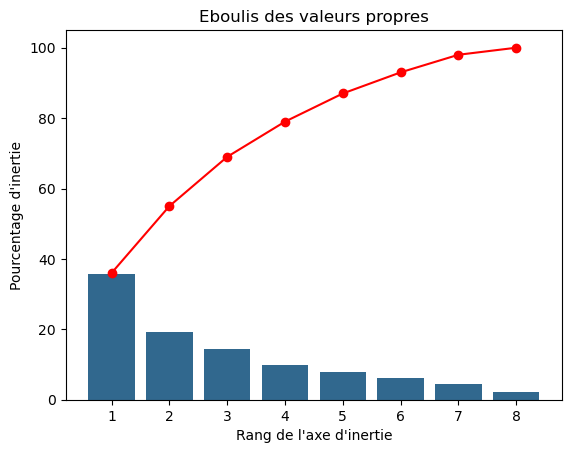

In [14]:
# Définisons ensuite une variable avec la liste de nos composantes :
x_list = range(1, n_components+1)
list(x_list)

# On peut enfin l'afficher de façon graphique : 
plt.bar(x_list, scree, color="#31688E")
plt.plot(x_list, scree_cum,c="red",marker='o')
plt.xlabel("Rang de l'axe d'inertie")
plt.ylabel("Pourcentage d'inertie")
plt.title("Eboulis des valeurs propres")
plt.savefig("Resultats/Ebolis_valeurs_propres_Red_8comp.png", transparent=True)
plt.show(block=False)

#plt.savefig("fig_Courbe_Lorenz_CA.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.


In [15]:
# On a en bleu la variance de chaque nouvelle composante, et en rouge la variance cumulée.
# On voit ici que près de 70% de la variance est comprise dans les 3 premières composantes, et près de 80% dans les 4 premières.


In [16]:
# Pour la suite de l'analyse, nous ne conservons que les composantes qui expliquent une part importante de la variation des données. 
# Nous relançons donc l'analyse avec seulement 5 composantes, ce qui explique 87 % de la variation.
# Nous allons travailler que sur les 5 premières composantes :
n_components = 5               

# On instancie notre ACP : 
pca = PCA(n_components=n_components)

# On l'entraine sur les données scalées :
pca.fit(X_scaled)


PCA(n_components=5)

In [17]:
# Intéressons nous maintenant à la variance captée par chaque nouvelle composante. 
# Grace à scikit-learn on peut utiliser l'attribut explained_variance_ratio_ :
pca.explained_variance_ratio_



array([0.35754538, 0.19113543, 0.14516748, 0.09752377, 0.08003761])

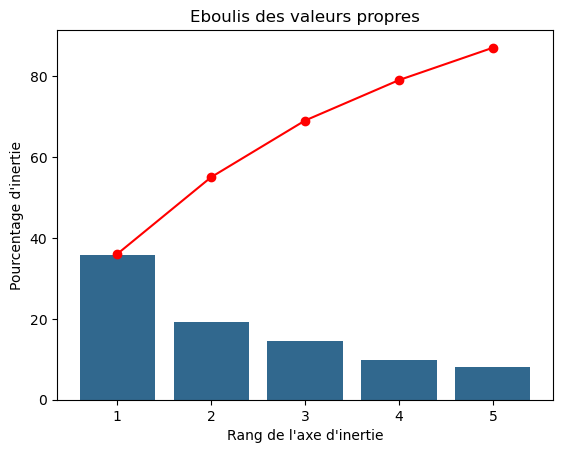

In [18]:
# Enregistrons cela dans une variable :
scree = (pca.explained_variance_ratio_*100).round(2)

# Somme cumulée  µ
scree_cum = scree.cumsum().round()

# Définisons ensuite une variable avec la liste de nos composantes :
x_list = range(1, n_components+1)
list(x_list)

# On peut enfin l'afficher de façon graphique : 
plt.bar(x_list, scree, color="#31688E")
plt.plot(x_list, scree_cum,c="red",marker='o')
plt.xlabel("Rang de l'axe d'inertie")
plt.ylabel("Pourcentage d'inertie")
plt.title("Eboulis des valeurs propres")
plt.show(block=False)

In [19]:
# 2.1.5 Components
# Par l'attribut components_, nommée pcs : 

pcs = pca.components_
pcs

array([[ 0.09333224,  0.39310769, -0.26765026,  0.08388164,  0.50197814,
        -0.15973506,  0.51511061,  0.46394651],
       [ 0.30777495,  0.37666521, -0.08429109,  0.61800043, -0.19685929,
         0.56391609, -0.13213277,  0.01242488],
       [ 0.66579429, -0.28572548, -0.57932747, -0.19360608, -0.09231259,
        -0.03925657,  0.14534541, -0.26605882],
       [ 0.4461659 , -0.01544198,  0.5673323 , -0.45977833,  0.18111449,
         0.44127771,  0.11188555,  0.1654951 ],
       [-0.49755191, -0.0371852 , -0.40715318, -0.31702703,  0.08112434,
         0.65696192,  0.18437961, -0.11226547]])

In [20]:
# Affichons la même chose mais version pandas : 
pcs = pd.DataFrame(pcs)
pcs.columns = features
pcs.index = [f"F{i}" for i in x_list]
pcs.round(2)

# pcs.T # transpose

,population,consumations,DIR2,consumption_trend,GNI_per_capita,distance_km,LPI,UPS
F1,0.09,0.39,-0.27,0.08,0.50,-0.16,0.52,0.46
F2,0.31,0.38,-0.08,0.62,-0.20,0.56,-0.13,0.01
F3,0.67,-0.29,-0.58,-0.19,-0.09,-0.04,0.15,-0.27
F4,0.45,-0.02,0.57,-0.46,0.18,0.44,0.11,0.17
F5,-0.50,-0.04,-0.41,-0.32,0.08,0.66,0.18,-0.11


<Axes: >

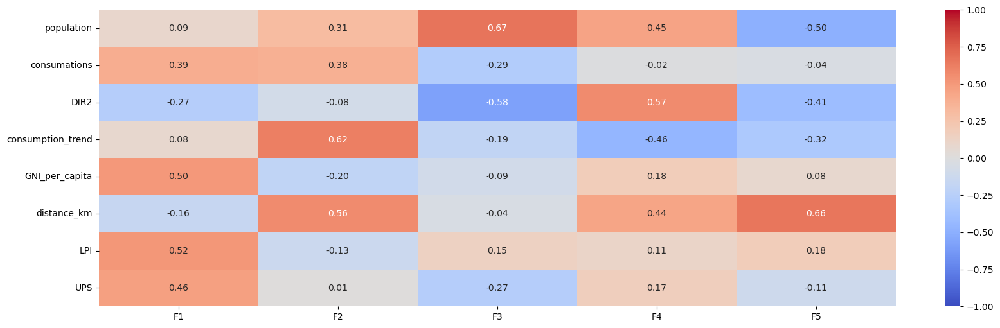

In [21]:
# Représentation plus visuelle, comme cela : 
fig, ax = plt.subplots(figsize=(20, 6))
sns.heatmap(pcs.T, vmin=-1, vmax=1, annot=True, cmap="coolwarm", fmt="0.2f")

In [22]:
# 2.1.6 Correlation graph
# Définissons nos axes x et y. Nous allons utiliser les 2 premières composantes: 
x, y = 0,1

In [23]:
# Function pour faire le cercle des correlations :
def correlation_graph(pca, 
                      x_y, 
                      features,
                      save=None) : 
    """Affiche le graphe des correlations

    Positional arguments : 
    -----------------------------------
    pca : sklearn.decomposition.PCA : notre objet PCA qui a été fit
    x_y : list ou tuple : le couple x,y des plans à afficher, exemple [0,1] pour F1, F2
    features : list ou tuple : la liste des features (ie des dimensions) à représenter
    save : str ou None : le chemin du fichier pour sauvegarder la figure, ou None pour ne pas la sauvegarder
    """

    # Extrait x et y 
    x,y=x_y

    # Taille de l'image (en inches)
    fig, ax = plt.subplots(figsize=(10, 9))

    # Pour chaque composante : 
    for i in range(0, pca.components_.shape[1]):

        # Les flèches
        ax.arrow(0,0, 
                pca.components_[x, i],  
                pca.components_[y, i],  
                head_width=0.07,
                head_length=0.07, 
                width=0.02, )

        # Les labels
        plt.text(pca.components_[x, i] + 0.05,
                pca.components_[y, i] + 0.05,
                features[i])
        
    # Affichage des lignes horizontales et verticales
    plt.plot([-1, 1], [0, 0], color='grey', ls='--')
    plt.plot([0, 0], [-1, 1], color='grey', ls='--')

    # Nom des axes, avec le pourcentage d'inertie expliqué
    plt.xlabel('F{} ({}%)'.format(x+1, round(100*pca.explained_variance_ratio_[x],1)))
    plt.ylabel('F{} ({}%)'.format(y+1, round(100*pca.explained_variance_ratio_[y],1)))

    # J'ai copié collé le code sans le lire
    plt.title("Cercle des corrélations (F{} et F{})".format(x+1, y+1))

    # Le cercle 
    an = np.linspace(0, 2 * np.pi, 100)
    plt.plot(np.cos(an), np.sin(an))  # Add a unit circle for scale

    # Axes, save, et display
    plt.axis('equal')
    if save is not None :
        fig.savefig(save, transparent=True, facecolor='none')
    plt.show(block=False)

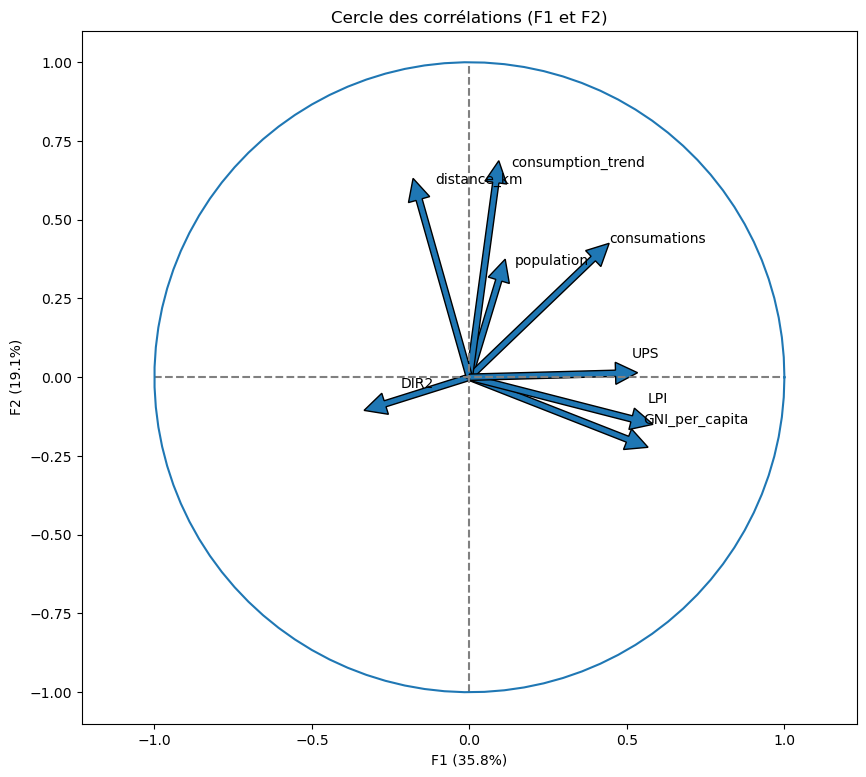

In [24]:
# Cercle des corrélations F1 et F2
x_y = (0,1)
x_y
correlation_graph(pca, x_y, features , save="Resultats/CC_F1F2_dat_red_trans.png")
plt.show()

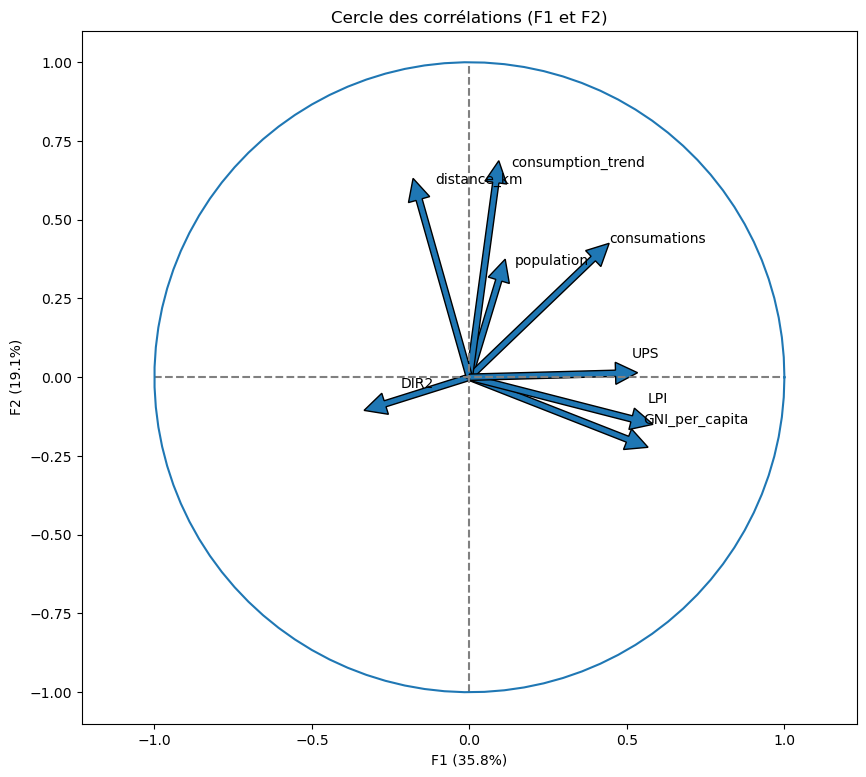

In [25]:
# Cercle des corrélations F1 et F2   # ANCIENNE DATA!!
x_y = (0,1)
x_y
correlation_graph(pca, x_y, features , save="Resultats/CC_F1F2_dat_red_trans.png")
plt.show()



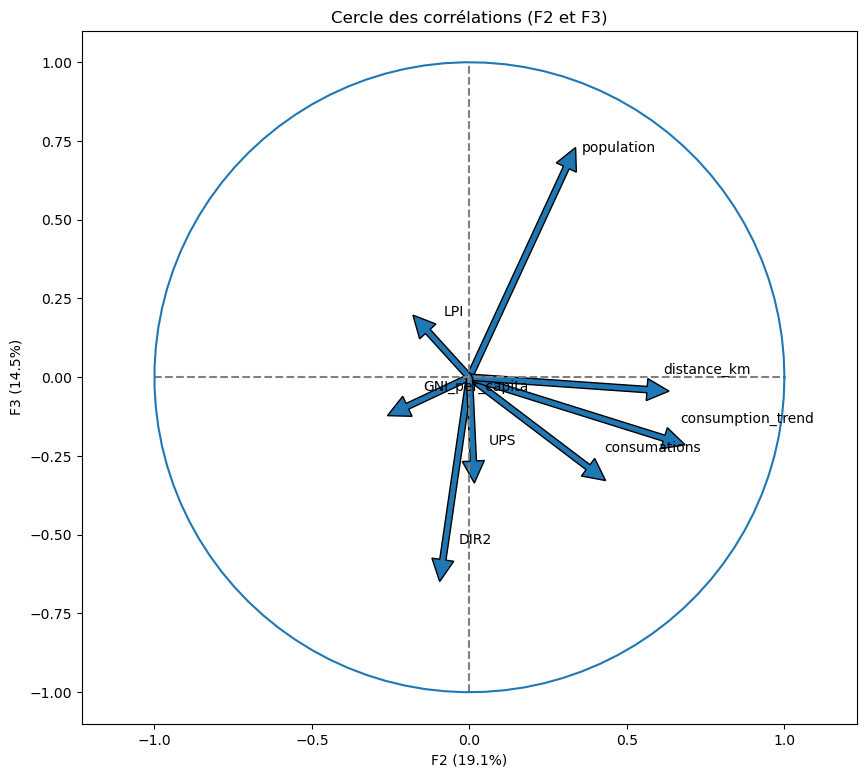

In [26]:
# Cercle des corrélations F2 et F3 : 
correlation_graph(pca, (1,2), features)


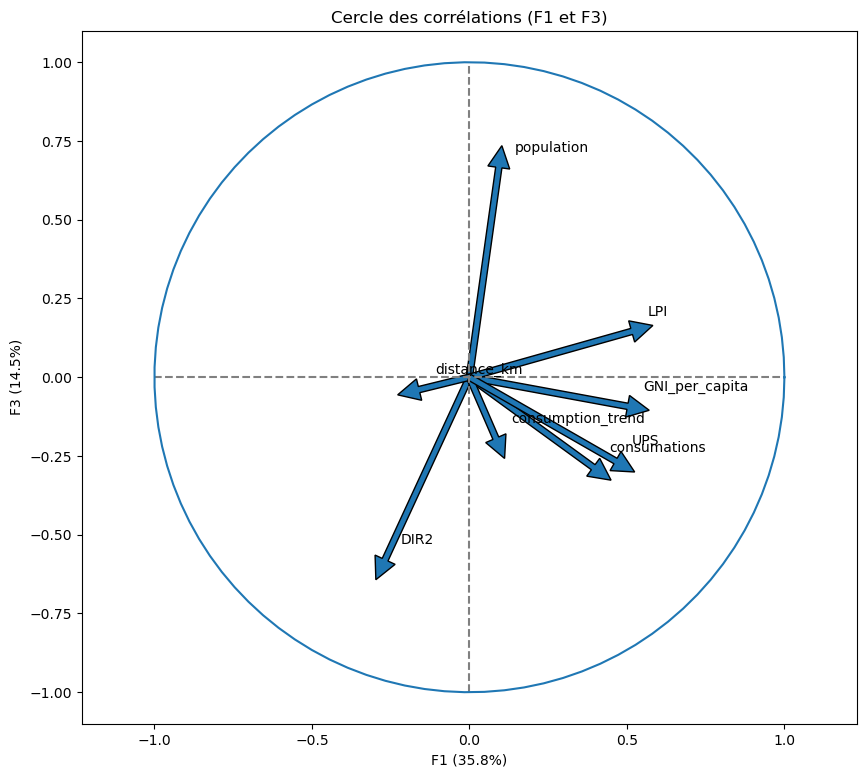

In [27]:
# Cercle des corrélations F1 et F3 : 
correlation_graph(pca, (0,2), features)


In [28]:
# 2.1.7 Projection
# Calculons les coordonnées de nos individus dans le nouvel espace : 
X_proj = pca.transform(X_scaled)
X_proj[:5]


array([[-2.76238983, -0.51292773,  0.58636702, -0.01798   , -0.13616769],
       [ 0.66769665,  1.27281991,  0.06587299,  0.3749181 ,  0.28636044],
       [-0.94051709, -1.51878975, -0.49901771,  0.21225259, -0.46843145],
       [-0.57394725, -1.01715829,  0.60395892, -0.4809902 , -0.66131183],
       [ 2.78491737, -1.42500531,  0.88112348,  0.69649618, -0.61283632]])

In [29]:
# Function pour aficher les observations projetées sur les composantes principales :

def display_factorial_planes(   X_projected, 
                                x_y, 
                                pca=None, 
                                labels = None,
                                clusters=None, 
                                alpha=1,
                                figsize=[10,8], 
                                marker="." ,
                                save=None):
    """
    Affiche la projection des individus

    Positional arguments : 
    -------------------------------------
    X_projected : np.array, pd.DataFrame, list of list : la matrice des points projetés
    x_y : list ou tuple : le couple x,y des plans à afficher, exemple [0,1] pour F1, F2
    
    Optional arguments : 
    -------------------------------------
    pca : sklearn.decomposition.PCA : un objet PCA qui a été fit, cela nous permettra d'afficher la variance de chaque composante, default = None
    labels : list ou tuple : les labels des individus à projeter, default = None
    clusters : list ou tuple : la liste des clusters auquel appartient chaque individu, default = None
    alpha : float in [0,1] : paramètre de transparence, 0=100% transparent, 1=0% transparent, default = 1
    figsize : list ou tuple : couple width, height qui définit la taille de la figure en inches, default = [10,8] 
    marker : str : le type de marker utilisé pour représenter les individus, points croix etc etc, default = "."
    save : str ou None : le chemin du fichier pour sauvegarder la figure, ou None pour ne pas la sauvegarder, default = None
    """

    # Transforme X_projected en np.array
    X_ = np.array(X_projected)

    # On définit la forme de la figure si elle n'a pas été donnée
    if not figsize: 
        figsize = (7,6)

    len(labels) # équivalent au code ci-dessous
#    # On gère les labels
#    if  labels is None : 
#        labels = []
#    try : 
#        len(labels)
#    except Exception as e : 
#        raise e

    # On vérifie la variable axis 
    if not len(x_y) ==2 : 
        raise AttributeError("2 axes sont demandées")   
    if max(x_y )>= X_.shape[1] : 
        raise AttributeError("la variable axis n'est pas bonne")   

    # on définit x et y 
    x, y = x_y

    # Initialisation de la figure       
    fig, ax = plt.subplots(1, 1, figsize=figsize)

    # On vérifie s'il y a des clusters ou non
    c = clusters  # équivalent au code ci-dessous
    # c = None if clusters is None else clusters
 
    # Les points    
    # plt.scatter(   X_[:, x], X_[:, y], alpha=alpha, 
    #                     c=c, cmap="Set1", marker=marker)
    sns.scatterplot(data=None, x=X_[:, x], y=X_[:, y], hue=c, style=c, color='#31688E', s=50)

    # Si la variable pca a été fournie, on peut calculer le % de variance de chaque axe 
    if pca : 
        v1 = str(round(100*pca.explained_variance_ratio_[x]))  + " %"
        v2 = str(round(100*pca.explained_variance_ratio_[y]))  + " %"
    else : 
        v1=v2= ''

    # Nom des axes, avec le pourcentage d'inertie expliqué
    ax.set_xlabel(f'F{x+1} {v1}')
    ax.set_ylabel(f'F{y+1} {v2}')

    # Valeur x max et y max
    x_max = np.abs(X_[:, x]).max() *1.1
    y_max = np.abs(X_[:, y]).max() *1.1

    # On borne x et y 
    ax.set_xlim(left=-x_max, right=x_max)
    ax.set_ylim(bottom= -y_max, top=y_max)

    # Affichage des lignes horizontales et verticales
    plt.plot([-x_max, x_max], [0, 0], color='grey', alpha=0.8)
    plt.plot([0,0], [-y_max, y_max], color='grey', alpha=0.8)

    # Affichage des labels des points
    if len(labels) : 
        # j'ai copié collé la fonction sans la lire
        for i,(_x,_y) in enumerate(X_[:,[x,y]]):
            plt.text(_x, _y+0.10, labels[i], fontsize='10', ha='center',va='center') 

    # Titre et display
    plt.title(f"Projection des individus (sur F{x+1} et F{y+1})")
    if save is not None :
        fig.savefig(save, transparent=True, facecolor='none')
    plt.show(block=False)
    plt.show()


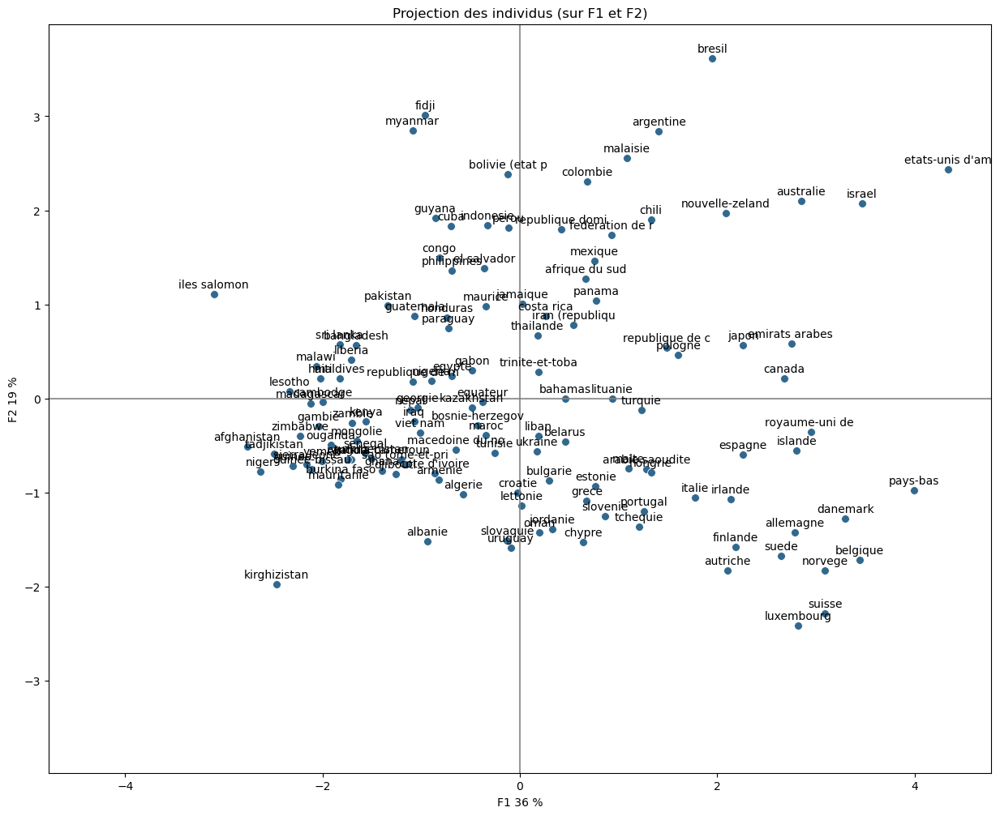

In [30]:
# La projection de nos dimensions avec F1 et F2 
x_y = [0,1]
display_factorial_planes(X_proj, x_y, pca, labels=names, figsize=(15,12), marker="o", save="Resultats/Proj_F1F2_dat_red_trans.png")


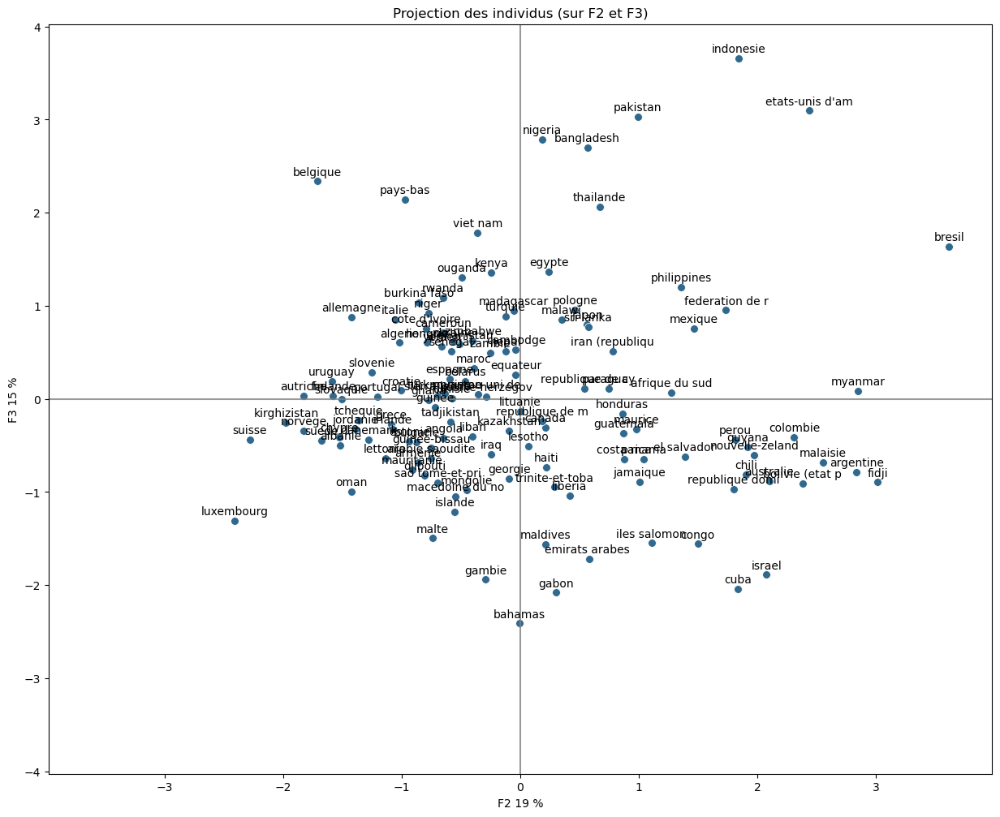

In [31]:
# La projection de nos dimensions avec F2 et F3 
x_y = 1,2
display_factorial_planes(X_proj, x_y, pca, labels=names, figsize=(15,12),marker="o")

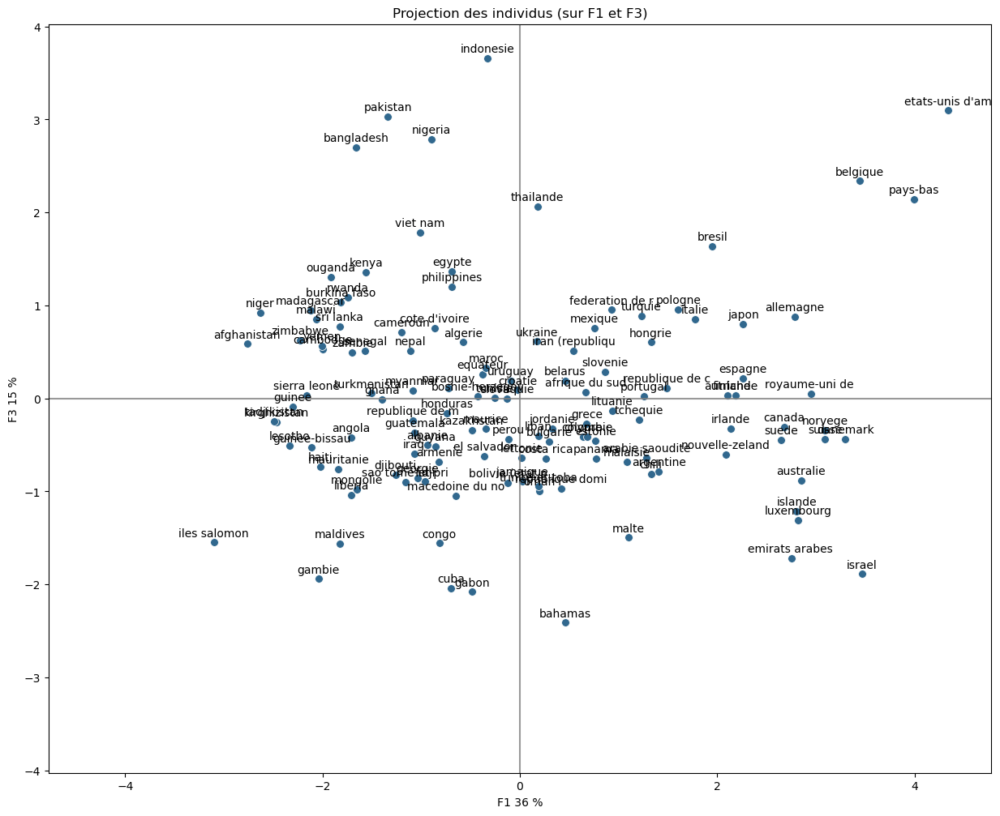

In [32]:
# La projection de nos dimensions avec F2 et F3 
x_y = 0,2
display_factorial_planes(X_proj, x_y, pca, labels=names, figsize=(15,12),marker="o")

In [33]:
# Sauvegardez nos nouvelles variables réduites - les composants
df_proj = pd.DataFrame(X_proj)
df_proj.columns = [f"F{i}" for i in x_list]
df_proj.index = names
df_proj


,F1,F2,F3,F4,F5
pays_norm,,,,,
afghanistan,-2.762390,-0.512928,0.586367,-0.017980,-0.136168
afrique du sud,0.667697,1.272820,0.065873,0.374918,0.286360
albanie,-0.940517,-1.518790,-0.499018,0.212253,-0.468431
algerie,-0.573947,-1.017158,0.603959,-0.480990,-0.661312
allemagne,2.784917,-1.425005,0.881123,0.696496,-0.612836
...,...,...,...,...,...
uruguay,-0.091643,-1.589568,0.190861,1.916047,2.220201
viet nam,-1.013587,-0.360442,1.786722,1.511746,0.874656
yemen,-2.003151,-0.665245,0.565517,-0.031951,0.176403


<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">2.2 - Partitione/Clustering</h3>
</div>

In [34]:
# Function pour afficher les observations projetées sur les composantes principales :
def display_factorial_planes_with_centroid(X_projected,
                                x_y,
                                Centroids_proj=None,  
                                pca=None, 
                                labels = None,
                                clusters=None, 
                                alpha=1,
                                figsize=[10,8], 
                                marker="." ,
                                save=None):
    """
    Affiche la projection des individus

    Positional arguments : 
    -------------------------------------
    X_projected : np.array, pd.DataFrame, list of list : la matrice des points projetés
    x_y : list ou tuple : le couple x,y des plans à afficher, exemple [0,1] pour F1, F2

    Optional arguments : 
    -------------------------------------
    Centroids_proj : pd.DataFrame ou np.array : la matrice des centroïdes projetés, default = None
    pca : sklearn.decomposition.PCA : un objet PCA qui a été fit, cela nous permettra d'afficher la variance de chaque composante, default = None
    labels : list ou tuple : les labels des individus à projeter, default = None
    clusters : list ou tuple : la liste des clusters auquel appartient chaque individu, default = None
    alpha : float in [0,1] : paramètre de transparence, 0=100% transparent, 1=0% transparent, default = 1
    figsize : list ou tuple : couple width, height qui définit la taille de la figure en inches, default = [10,8] 
    marker : str : le type de marker utilisé pour représenter les individus, points croix etc etc, default = "."
    save : str ou None : le chemin du fichier pour sauvegarder la figure, ou None pour ne pas la sauvegarder, default = None
    """

    # Transforme X_projected en np.array
    X_ = np.array(X_projected)

    # On définit la forme de la figure si elle n'a pas été donnée
    if not figsize: 
        figsize = (7,6)

    len(labels) # équivalent au code ci-dessous

    # On vérifie la variable axis 
    if not len(x_y) ==2 : 
        raise AttributeError("2 axes sont demandées")   
    if max(x_y )>= X_.shape[1] : 
        raise AttributeError("la variable axis n'est pas bonne")   

    # on définit x et y 
    x, y = x_y

    # Initialisation de la figure       
    fig, ax = plt.subplots(1, 1, figsize=figsize)
    
    # définir les couleurs
    #col = sns.color_palette("viridis_r",len(np.unique(clusters)))
    n = len(np.unique(clusters))
    cmap = plt.get_cmap("viridis_r")
    colors = [cmap(x) for x in np.linspace(0, 1, n)]

    # On vérifie s'il y a des clusters ou non
    c = clusters  # équivalent au code ci-dessous
    # c = None if clusters is None else clusters
 
    # Les points    
    sns.scatterplot(data=None, x=X_[:, x], y=X_[:, y], hue=c, style=c, palette=colors, s=200)
    if Centroids_proj is not None:
        ax.scatter(Centroids_proj.iloc[:, x], Centroids_proj.iloc[:, y],  marker='*', color=colors, s=600) #, c="black")

    # Si la variable pca a été fournie, on peut calculer le % de variance de chaque axe 
    if pca : 
        v1 = str(round(100*pca.explained_variance_ratio_[x]))  + " %"
        v2 = str(round(100*pca.explained_variance_ratio_[y]))  + " %"
    else : 
        v1=v2= ''

    # Nom des axes, avec le pourcentage d'inertie expliqué
    ax.set_xlabel(f'F{x+1} {v1}', fontsize=14)
    ax.set_ylabel(f'F{y+1} {v2}', fontsize=14)

    # Valeur x max et y max
    x_max = np.abs(X_[:, x]).max() *1.1
    y_max = np.abs(X_[:, y]).max() *1.1

    # On borne x et y 
    ax.set_xlim(left=-x_max, right=x_max)
    ax.set_ylim(bottom= -y_max, top=y_max)

    # Affichage des lignes horizontales et verticales
    plt.plot([-x_max, x_max], [0, 0], color='grey', alpha=0.8)
    plt.plot([0,0], [-y_max, y_max], color='grey', alpha=0.8)

    # Affichage des labels des points
    if len(labels) : 
        # j'ai copié collé la fonction sans la lire
        for i,(_x,_y) in enumerate(X_[:,[x,y]]):
            plt.text(_x, _y+0.10, labels[i], fontsize='12', ha='center',va='center') 
    
    title = ' ' if clusters is None else 'cluster'
    plt.legend(title=title, fontsize=12)
    #c = None if clusters is None else clusters
    # Titre, save, et display
    plt.title(f"Projection des individus (sur F{x+1} et F{y+1})", fontsize=14)
    if save is not None : 
        fig.savefig(save, dpi=300, bbox_inches="tight", transparent=True)
        print("Figure saved") 
    plt.show()

#display_factorial_planes_with_centroid(X_proj, x_y, centroids_proj, pca, labels_pays=names, labels_clust_nr=labels_nr, figsize=(20,16), clusters=clusters, marker="o")

<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 10px; color: RGB(255,255,255); ">2.2.1 - Classifications sur les données brutes</h3>
</div>

<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 10px; color: RGB(255,255,255); ">2.2.1.1 - Classifications ascendante hierarchical - sur les données brutes </h3>
</div>

In [35]:
# les données brute
#df.drop(columns="cluster",inplace=True)
X = df
X.head()


,population,consumations,DIR2,consumption_trend,GNI_per_capita,distance_km,LPI,UPS
pays_norm,,,,,,,,
afghanistan,36296113.0,1.53,0.527273,-0.038929,530.0,5597.877813,1.95,24.835282
afrique du sud,57009756.0,35.69,0.221622,0.532500,5850.0,8654.323509,3.38,63.331108
albanie,2884169.0,16.36,0.808511,-0.399762,4700.0,1605.053520,2.66,55.980276
algerie,41389189.0,6.38,0.007576,-0.015833,4440.0,1337.880037,2.45,71.322791
allemagne,82658409.0,19.47,0.121815,-0.029048,44730.0,440.324090,4.20,80.984254


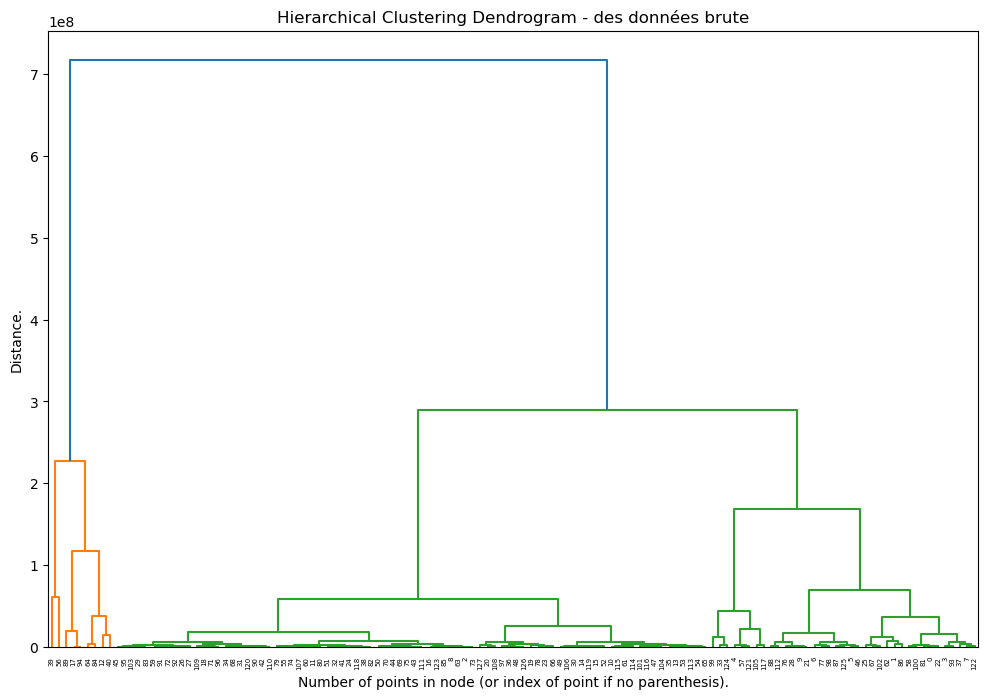

In [36]:
# Calculer les distances utilisant la méthode de Ward:
Z = linkage(X, method="ward")

# Afficher le dendrogramme: 
fig, ax = plt.subplots(1, 1, figsize=(12, 8))

_ = dendrogram(Z, ax=ax)

plt.title("Hierarchical Clustering Dendrogram - des données brute")
plt.xlabel("Number of points in node (or index of point if no parenthesis).")
plt.ylabel("Distance.")
plt.show()

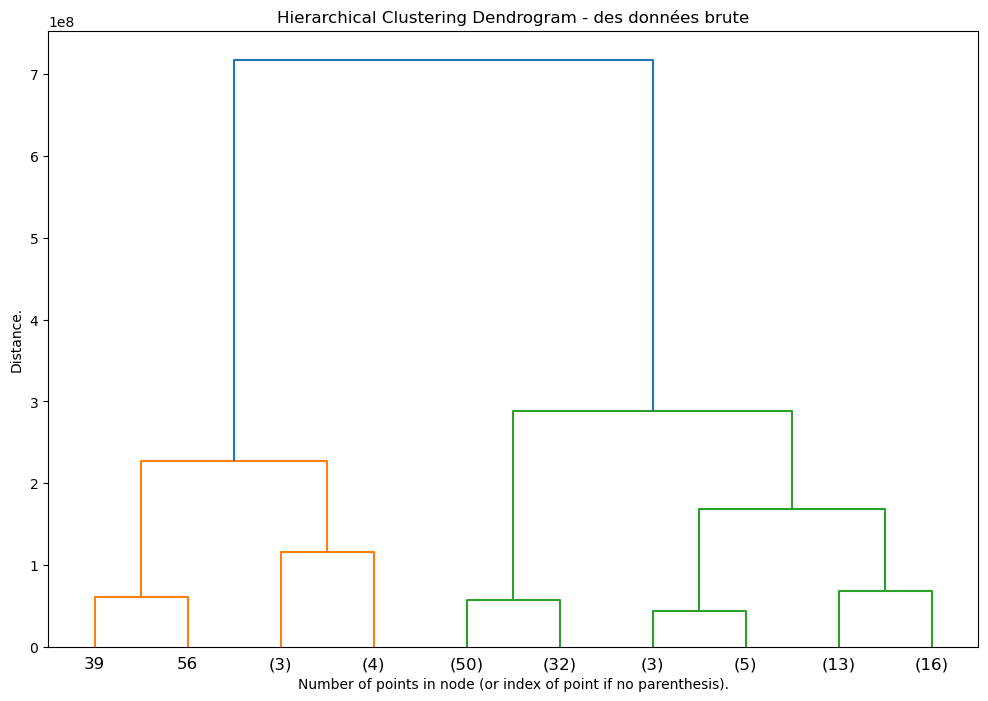

In [37]:
fig, ax = plt.subplots(1, 1, figsize=(12, 8))

_ = dendrogram(Z, p=10, truncate_mode="lastp", ax=ax)

plt.title("Hierarchical Clustering Dendrogram - des données brute")
plt.xlabel("Number of points in node (or index of point if no parenthesis).")
plt.ylabel("Distance.")
plt.show()

In [38]:
#  les arguments p=3, truncate_mode="level"signifient que l'on ne va afficher que les clusters issus de 3 noeuds.
#fig, ax = plt.subplots(1, 1, figsize=(12, 8))

##_ = dendrogram(Z, p=5, truncate_mode="level", ax=ax)

#plt.title("Hierarchical Clustering Dendrogram - des données brute")
#plt.xlabel("Number of points in node (or index of point if no parenthesis).")
#plt.show()

In [39]:
# Défini le nombre de clusters que l'on souhaite:
k=3
print("Nombres de clusters:", k)
print("L'analyse de regroupement indique 2 groupes distincts, mais compte tenu de l'objectif de notre travail, \navoir plus de groupes avec moins de pays dans chaque groupe est plus facile à gérer et peut nous fournir des informations supplémentaires entre ces groupes.\n\n")
print("Cependant, on constate déjà que l'analyse de regroupement ne donne pas de résultats satisfaisants sur nos données. \nLa plupart des pays étant regroupés dans les mêmes clusters. Nous souhaiterions un regroupement plus performant, \npermettant de mieux distinguer les différences entre les pays.")


Nombres de clusters: 3
L'analyse de regroupement indique 2 groupes distincts, mais compte tenu de l'objectif de notre travail, 
avoir plus de groupes avec moins de pays dans chaque groupe est plus facile à gérer et peut nous fournir des informations supplémentaires entre ces groupes.


Cependant, on constate déjà que l'analyse de regroupement ne donne pas de résultats satisfaisants sur nos données. 
La plupart des pays étant regroupés dans les mêmes clusters. Nous souhaiterions un regroupement plus performant, 
permettant de mieux distinguer les différences entre les pays.


In [40]:
# On instancie un estimateur  
cah = AgglomerativeClustering(n_clusters=k, linkage="ward")

# On entraine l'estimateur 
cah.fit(X)

# Pour être plus clair, nous allons utiliser des lettres plutôt que des nombres:
dd = {i:j for i,j in enumerate(list("abcde"))}
labels = [dd[i] for i in cah.labels_]
labels[:10]

# Ajoutons nos labels à X
X["cluster"] = labels
X.head()


,population,consumations,DIR2,consumption_trend,GNI_per_capita,distance_km,LPI,UPS,cluster
pays_norm,,,,,,,,,
afghanistan,36296113.0,1.53,0.527273,-0.038929,530.0,5597.877813,1.95,24.835282,b
afrique du sud,57009756.0,35.69,0.221622,0.532500,5850.0,8654.323509,3.38,63.331108,b
albanie,2884169.0,16.36,0.808511,-0.399762,4700.0,1605.053520,2.66,55.980276,c
algerie,41389189.0,6.38,0.007576,-0.015833,4440.0,1337.880037,2.45,71.322791,b
allemagne,82658409.0,19.47,0.121815,-0.029048,44730.0,440.324090,4.20,80.984254,b


In [41]:
# Définir les couleurs des figures
#cmap = plt.get_cmap("viridis_r")
#colors = [cmap(x) for x in np.linspace(0, 1, k)]

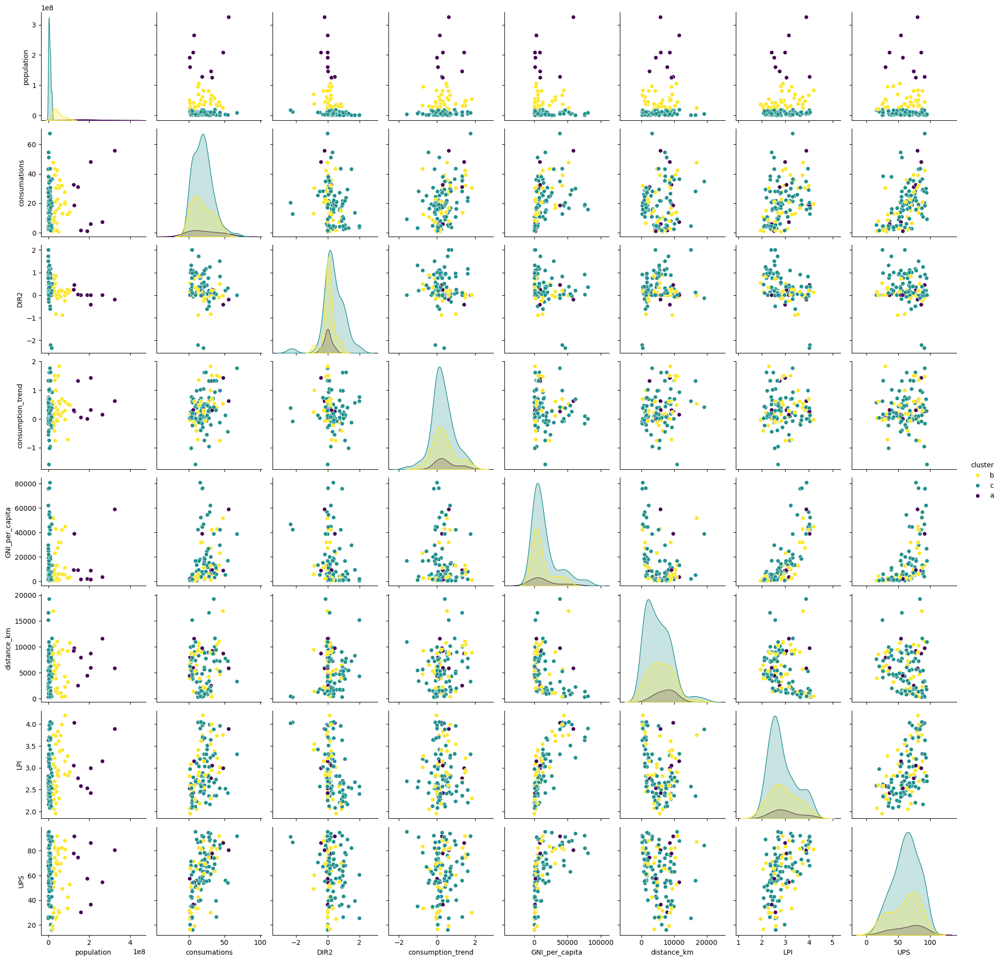

In [42]:
# Observons nos clusters sur le pairplot:
cmap = plt.get_cmap("viridis_r")
colors = [cmap(x) for x in np.linspace(0, 1, k)] 
sns.pairplot(X, hue="cluster",palette=colors)

In [43]:
# Afficher les pays pour chaque cluster : 

# Applique ensuite la fonction fclustersde scipypour définir les clusters : 
clusters = fcluster(Z, k, criterion='maxclust')

# Faire une table de contingence pour identifier les pays dans chaque cluster
crosstab = pd.crosstab(names, clusters, dropna=False)
crosstab.rename_axis(columns="cluster", index="theme", inplace=True)
crosstab

# Ranger les données
df_list = pd.DataFrame({"name" : names, "cluster" : clusters})
df_list.head()

# Afficher les pays
for i in range(1, 6) : 
    # on fait une selection
    sub_df = df_list.loc[df_list.cluster == i]

    # le cluster en question
    print(f"cluster : {i}")

    # on extrait les noms et les themes de chaque ligne
    names_list = sub_df.name.values
    #themes_list = sub_df.theme.values

    # on créé une liste de couple nom/theme
    ziped = names_list 
    txt = names_list

    # on transforme en str
    txt = " / ".join(txt)
 
    # on print
    print(txt)
    print("\n\n")

#X["clusters_kmeans"] = clusters    # attacher les clusters au dataframe

cluster : 1
bangladesh / bresil / etats-unis d'am / federation de r / indonesie / japon / mexique / nigeria / pakistan



cluster : 2
albanie / armenie / autriche / bahamas / belarus / belgique / bolivie (etat p / bosnie-herzegov / bulgarie / burkina faso / cambodge / chili / chypre / congo / costa rica / croatie / cuba / danemark / djibouti / el salvador / emirats arabes  / equateur / estonie / fidji / finlande / gabon / gambie / georgie / grece / guatemala / guinee / guinee-bissau / guyana / haiti / honduras / hongrie / iles salomon / irlande / islande / israel / jamaique / jordanie / kazakhstan / kirghizistan / lesotho / lettonie / liban / liberia / lituanie / luxembourg / macedoine du no / malawi / maldives / malte / maurice / mauritanie / mongolie / norvege / nouvelle-zeland / oman / panama / paraguay / pays-bas / portugal / republique de m / republique domi / rwanda / sao tome-et-pri / senegal / sierra leone / slovaquie / slovenie / suede / suisse / tadjikistan / tchequie / trini

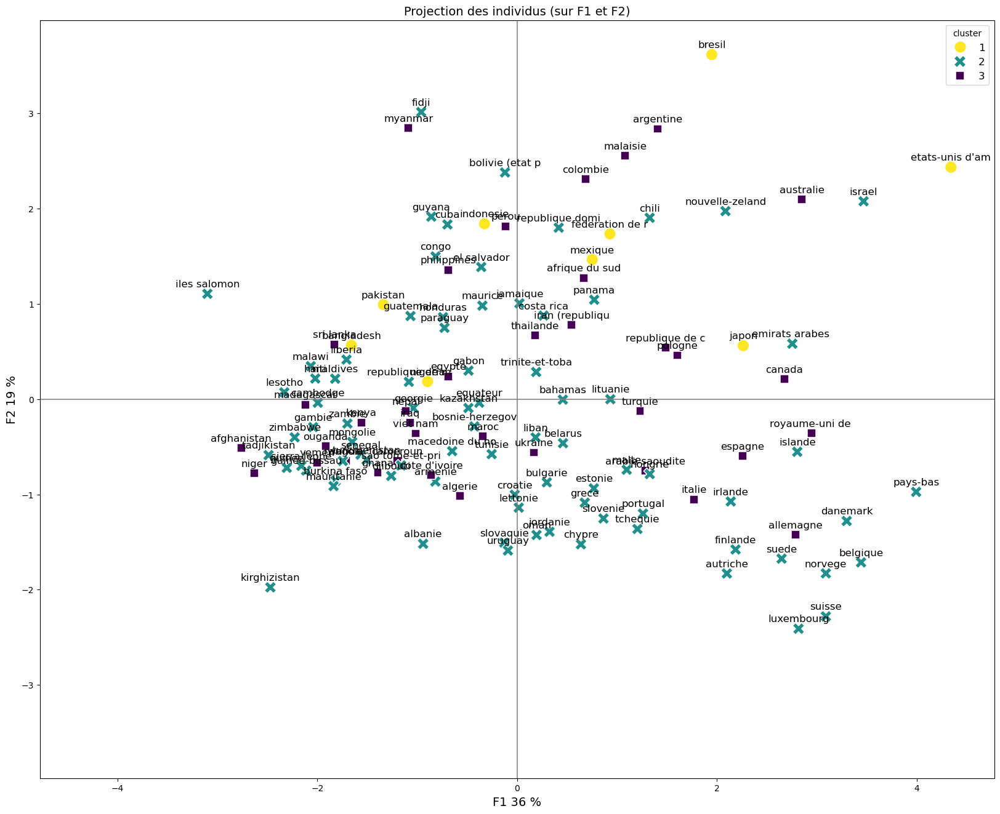

In [44]:
# Afficher le plane factorial avec les clusters en differents coleurs :
x_y = [0,1]
#display_factorial_planes(X_proj, x_y, pca, labels=names, figsize=(20,16), clusters=clusters, marker="o")
display_factorial_planes_with_centroid(X_proj, x_y, None, pca, labels=names, figsize=(20,16), clusters=clusters, marker="o")

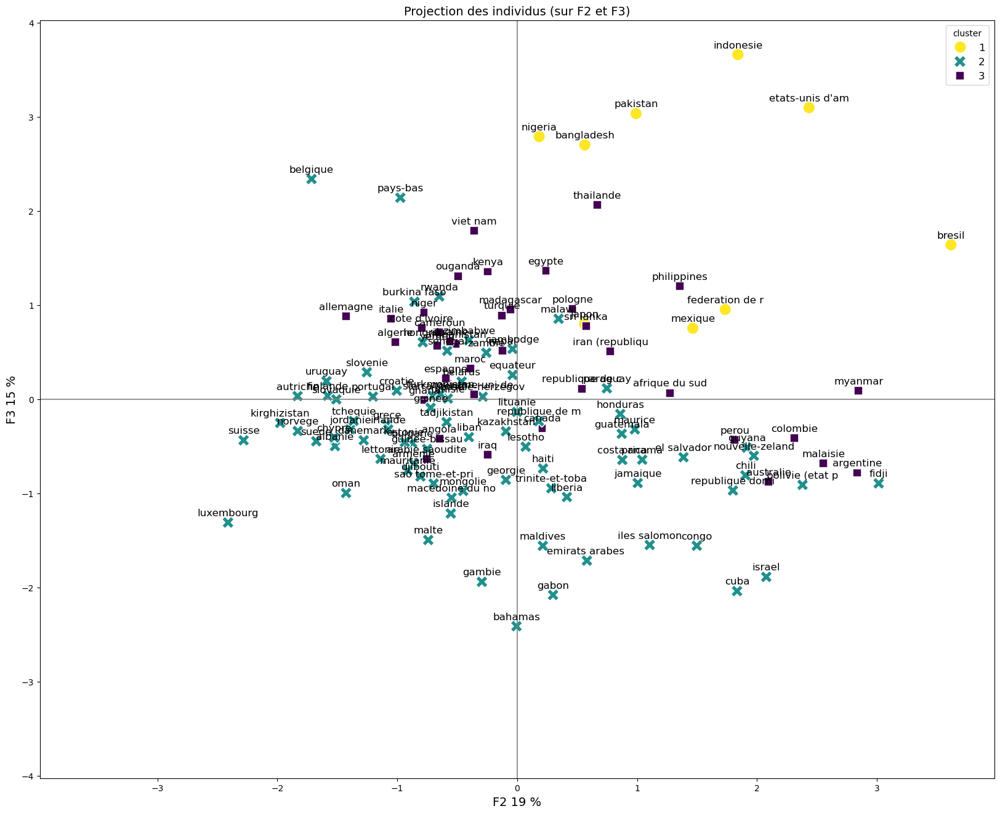

In [45]:
# Afficher le plane factorial avec les clusters en differents coleurs :
x_y = [1,2]
display_factorial_planes_with_centroid(X_proj, x_y, None, pca, labels=names, figsize=(20,16), clusters=clusters, marker="o")

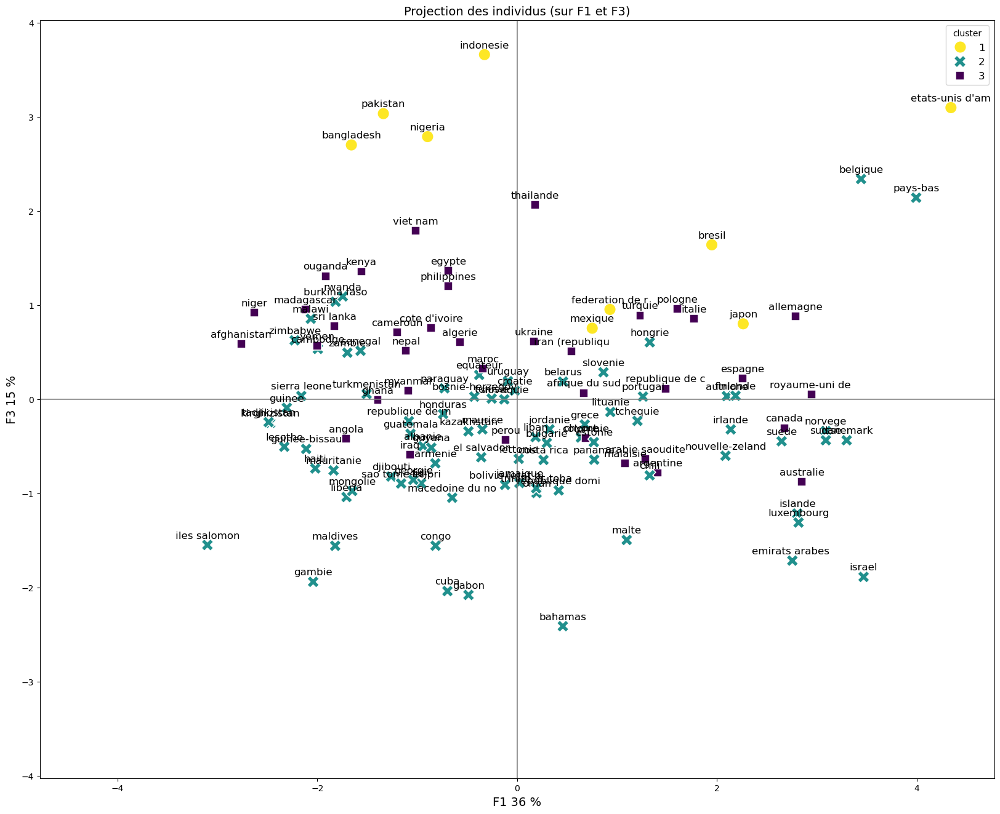

In [46]:
# Afficher le plane factorial avec les clusters en differents coleurs :
x_y = [0,2]
display_factorial_planes_with_centroid(X_proj, x_y, None, pca, labels=names, figsize=(20,16), clusters=clusters, marker="o")

Text(0.5, 0, 'F3')

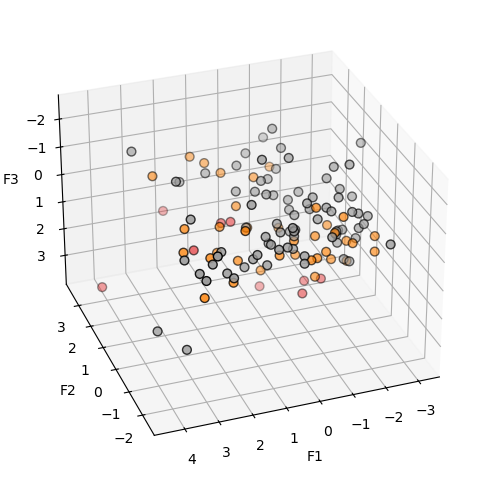

In [47]:
# Graphique 3D avec les clusters en differents coleurs 

fig= plt.figure(1, figsize=(8, 6))
x_proj = pd.DataFrame(X_proj)

ax = fig.add_subplot(111, projection="3d", elev=-150, azim=110)
ax.scatter(
    x_proj.iloc[:, 0],
    x_proj.iloc[:, 1],
    x_proj.iloc[:, 2],
    c=cah.labels_,                     
    cmap=plt.cm.Set1,
    edgecolor="k",
    s=40)

ax.set_xlabel("F1")
ax.set_ylabel("F2")
ax.set_zlabel("F3")

In [48]:
# Conclusions les analyse de regroupement sur les données brutes:
print("Conclusions les analyse de regroupement sur les données brutes:\n")
print("L'analyse de regroupement sur les données brutes ne donne pas de résultats satisfaisants. \nLa plupart des pays étant regroupés dans les mêmes clusters, Et les groupes visualisés sur la projection de factoriel ont montré un motif très dispersé. \nNous souhaiterions un regroupement plus performant, permettant de mieux distinguer les différences entre les pays.")

Conclusions les analyse de regroupement sur les données brutes:

L'analyse de regroupement sur les données brutes ne donne pas de résultats satisfaisants. 
La plupart des pays étant regroupés dans les mêmes clusters, Et les groupes visualisés sur la projection de factoriel ont montré un motif très dispersé. 
Nous souhaiterions un regroupement plus performant, permettant de mieux distinguer les différences entre les pays.


<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 10px; color: RGB(255,255,255); ">2.2.1.2 - Classifications k-means - sur les données brute </h3>
</div>

In [51]:
# Les données brutes
df.drop(columns="cluster",inplace=True)
X = df.copy()
X.head()


,population,consumations,DIR2,consumption_trend,GNI_per_capita,distance_km,LPI,UPS
pays_norm,,,,,,,,
afghanistan,36296113.0,1.53,0.527273,-0.038929,530.0,5597.877813,1.95,24.835282
afrique du sud,57009756.0,35.69,0.221622,0.532500,5850.0,8654.323509,3.38,63.331108
albanie,2884169.0,16.36,0.808511,-0.399762,4700.0,1605.053520,2.66,55.980276
algerie,41389189.0,6.38,0.007576,-0.015833,4440.0,1337.880037,2.45,71.322791
allemagne,82658409.0,19.47,0.121815,-0.029048,44730.0,440.324090,4.20,80.984254


In [52]:
# Identifier le nombre optimal de clusters
# Une liste vide pour enregistrer les inerties :  
intertia_list = [ ]

# Notre liste de nombres de clusters : 
k_list = range(1, 10)

# Pour chaque nombre de clusters : 
for k in k_list : 
    
    # On instancie un k-means pour k clusters
    kmeans = KMeans(n_clusters=k)
    
    # On entraine
    kmeans.fit(X)
    
    # On enregistre l'inertie obtenue : 
    intertia_list.append(kmeans.inertia_)



c:\Users\matil\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\matil\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\matil\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\matil\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Window

L'inertie diminue drastiquement jusqu'à 3 ou 4 clusters


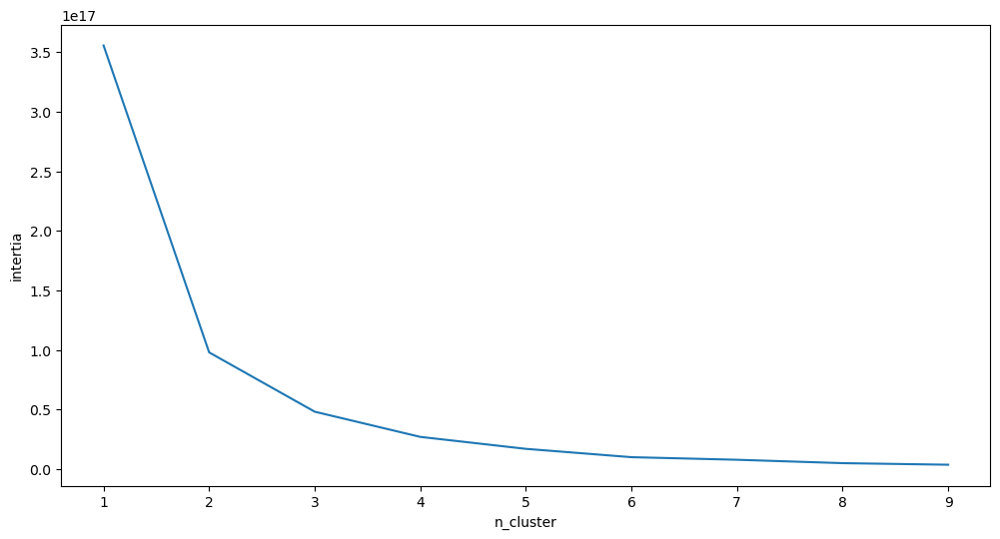

In [53]:
# Afficher le resultat, les liste d'inertie :
fig, ax = plt.subplots(1,1,figsize=(12,6))

print("L'inertie diminue drastiquement jusqu'à 3 ou 4 clusters")

ax.set_ylabel("intertia")
ax.set_xlabel("n_cluster")

ax = plt.plot(k_list, intertia_list)


In [54]:
# Défini le nombre de clusters que l'on souhaite:
k=4
print("Nombres de clusters:", k)

Nombres de clusters: 4


In [55]:
# Les clusters que nous avons obtenus
kmeans = KMeans(n_clusters=k)
kmeans.fit(X)
labels_nr = kmeans.labels_
labels_nr


c:\Users\matil\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


array([0, 0, 2, 0, 0, 0, 0, 0, 2, 2, 2, 2, 3, 2, 2, 2, 2, 1, 2, 2, 2, 2,
       0, 2, 2, 0, 2, 2, 2, 2, 2, 2, 2, 3, 2, 2, 2, 0, 2, 1, 3, 2, 2, 2,
       2, 2, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 0, 0, 2, 2, 2, 0, 2, 3, 2,
       2, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 2, 2, 2, 0, 2, 2, 3, 2, 0, 0,
       2, 1, 2, 2, 2, 0, 1, 2, 2, 2, 0, 3, 0, 2, 0, 2, 2, 0, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 0, 2, 2, 2, 0, 0, 2, 3, 0, 2, 2])

In [56]:
# nous allons utiliser des lettres plutôt que des nombres: 
dd = {i:j for i,j in enumerate(list("abcde"))}

clusters = [dd[i] for i in kmeans.labels_]

# Ajoutons nos labels à X
X["cluster"] = clusters
X.head()

,population,consumations,DIR2,consumption_trend,GNI_per_capita,distance_km,LPI,UPS,cluster
pays_norm,,,,,,,,,
afghanistan,36296113.0,1.53,0.527273,-0.038929,530.0,5597.877813,1.95,24.835282,a
afrique du sud,57009756.0,35.69,0.221622,0.532500,5850.0,8654.323509,3.38,63.331108,a
albanie,2884169.0,16.36,0.808511,-0.399762,4700.0,1605.053520,2.66,55.980276,c
algerie,41389189.0,6.38,0.007576,-0.015833,4440.0,1337.880037,2.45,71.322791,a
allemagne,82658409.0,19.47,0.121815,-0.029048,44730.0,440.324090,4.20,80.984254,a


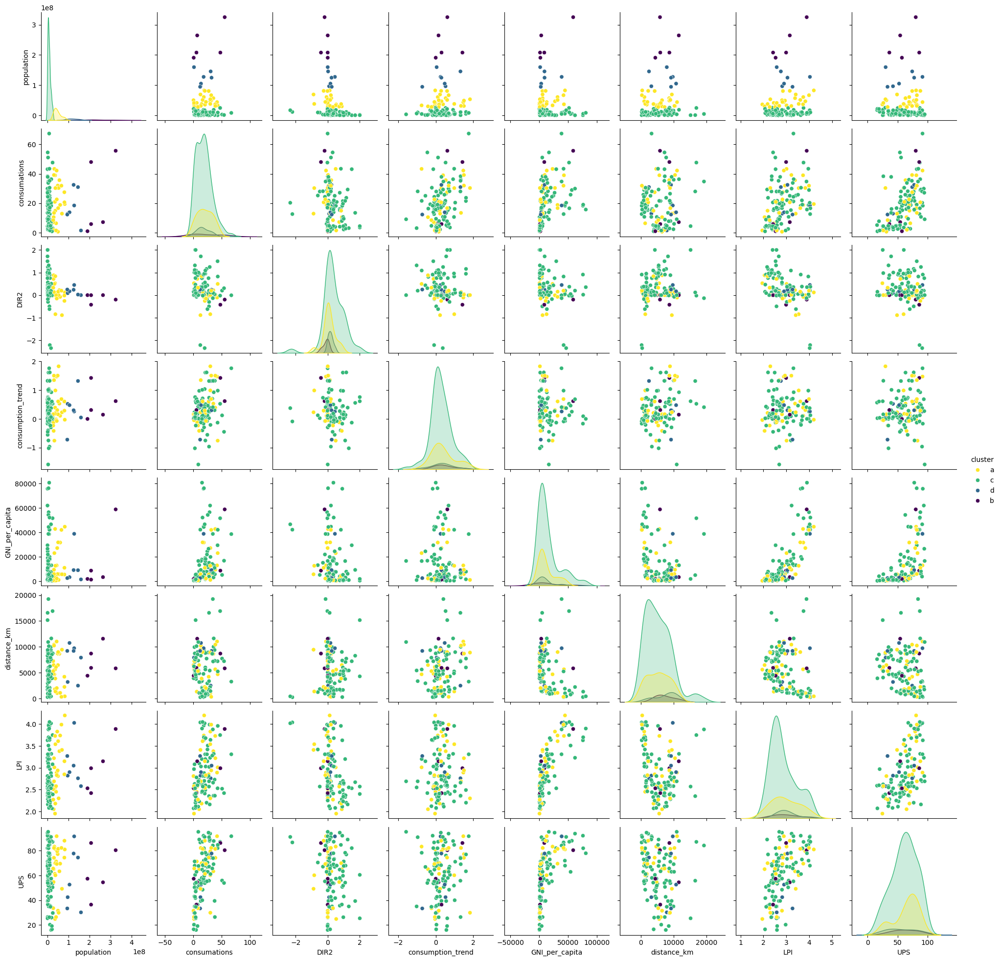

In [57]:
# Affichons le graphique avec les groupes identifiés sont codés par couleur (methode de Kmeans):
colors = [cmap(x) for x in np.linspace(0, 1, k)] 
sns.pairplot(X, hue="cluster",palette=colors)


In [58]:
# Enregistrons nos centroids 
centroids = kmeans.cluster_centers_
print(centroids.shape)
centroids


(4, 8)


array([[ 4.69099543e+07,  2.07532143e+01,  8.47158094e-02,
         4.07402211e-01,  1.22992857e+04,  5.30939831e+03,
         2.97214286e+00,  6.50790823e+01],
       [ 2.39269799e+08,  2.35540000e+01, -1.24212023e-01,
         5.00309524e-01,  1.49420000e+04,  7.29838774e+03,
         2.99600000e+00,  6.29676097e+01],
       [ 8.04453515e+06,  1.87962500e+01,  3.47594796e-01,
         2.77700216e-01,  1.51947727e+04,  5.30740118e+03,
         2.85727273e+00,  6.11997961e+01],
       [ 1.21958817e+08,  1.75228571e+01,  1.73721867e-01,
         3.15745064e-01,  9.71428571e+03,  7.50860893e+03,
         3.05857143e+00,  5.74777709e+01]])

In [59]:
# scaler les centroids
centroids_scaled = scaler.fit_transform(centroids)
centroids_scaled.shape

(4, 8)

In [60]:
# Créons un DataFrame pour plus de clarté :                     ADJUST AFTER NUMBER OF CLUSTERS AND COMPONENTS
centroids_proj = pca.transform(centroids_scaled)
centroids_proj = pd.DataFrame(centroids_proj, 
                              columns = ["F1", "F2", "F3", "F4", "F5"], 
                              index=["cluster_1", "cluster_2", "cluster_3", "cluster_4"])
centroids_proj 

,F1,F2,F3,F4,F5
cluster_1,0.696545,-0.336420,-0.709016,-0.880075,-0.535240
cluster_2,1.913787,2.350575,0.960538,-0.156550,-0.022053
cluster_3,-1.028249,-1.922118,-1.340233,0.333432,-0.467022
cluster_4,-1.582083,-0.092037,1.088711,0.703192,1.024315


In [61]:
# Valeurs des centroïdes sur les données originales                     ADJUST AFTER NUMBER OF CLUSTERS
centroids_brute = pd.DataFrame(centroids, 
                              columns = features, 
                              index = ["cluster_1", "cluster_2", "cluster_3", "cluster_4"])

centroids_brute

,population,consumations,DIR2,consumption_trend,GNI_per_capita,distance_km,LPI,UPS
cluster_1,4.690995e+07,20.753214,0.084716,0.407402,12299.285714,5309.398307,2.972143,65.079082
cluster_2,2.392698e+08,23.554000,-0.124212,0.500310,14942.000000,7298.387739,2.996000,62.967610
cluster_3,8.044535e+06,18.796250,0.347595,0.277700,15194.772727,5307.401175,2.857273,61.199796
cluster_4,1.219588e+08,17.522857,0.173722,0.315745,9714.285714,7508.608934,3.058571,57.477771


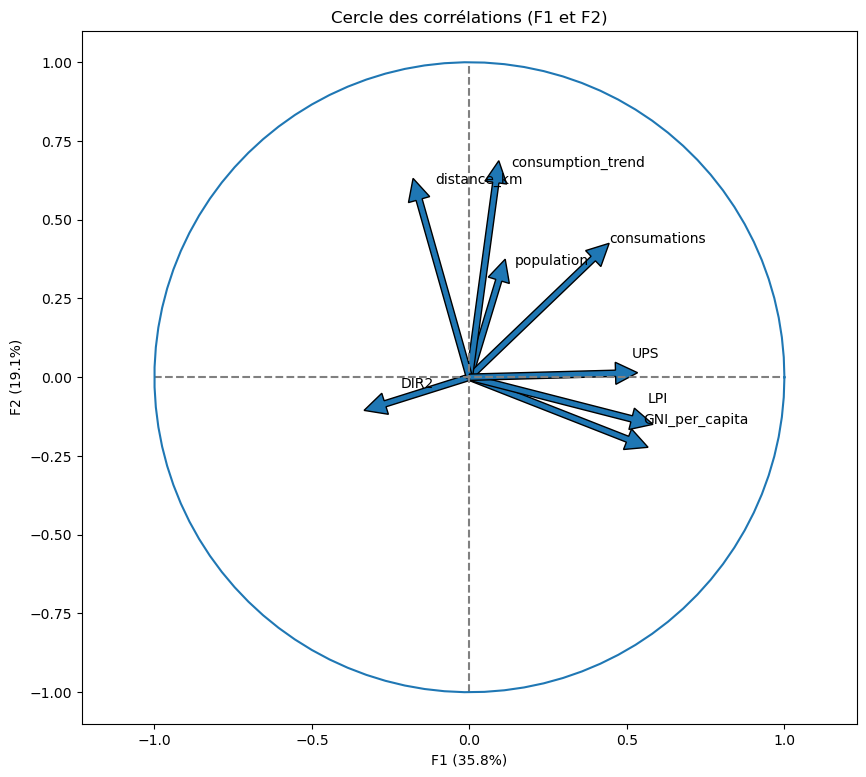

In [62]:
# Cercle des corrélations F1 et F2
x_y = (0,1)
x_y
correlation_graph(pca, x_y, features)

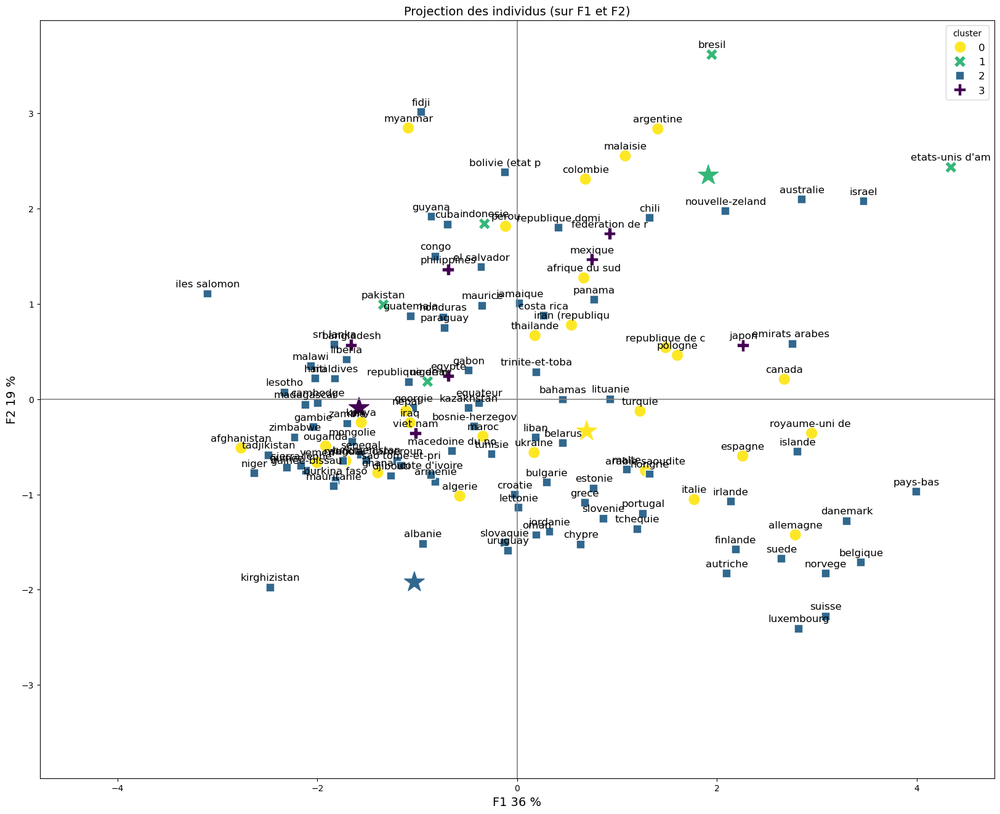

In [63]:
# Afficher le plane factorial avec les clusters en differents coleurs :
x_y = [0,1]
display_factorial_planes_with_centroid(X_proj, x_y, centroids_proj, pca, labels=names, figsize=(20,16), clusters=kmeans.labels_, marker="o")

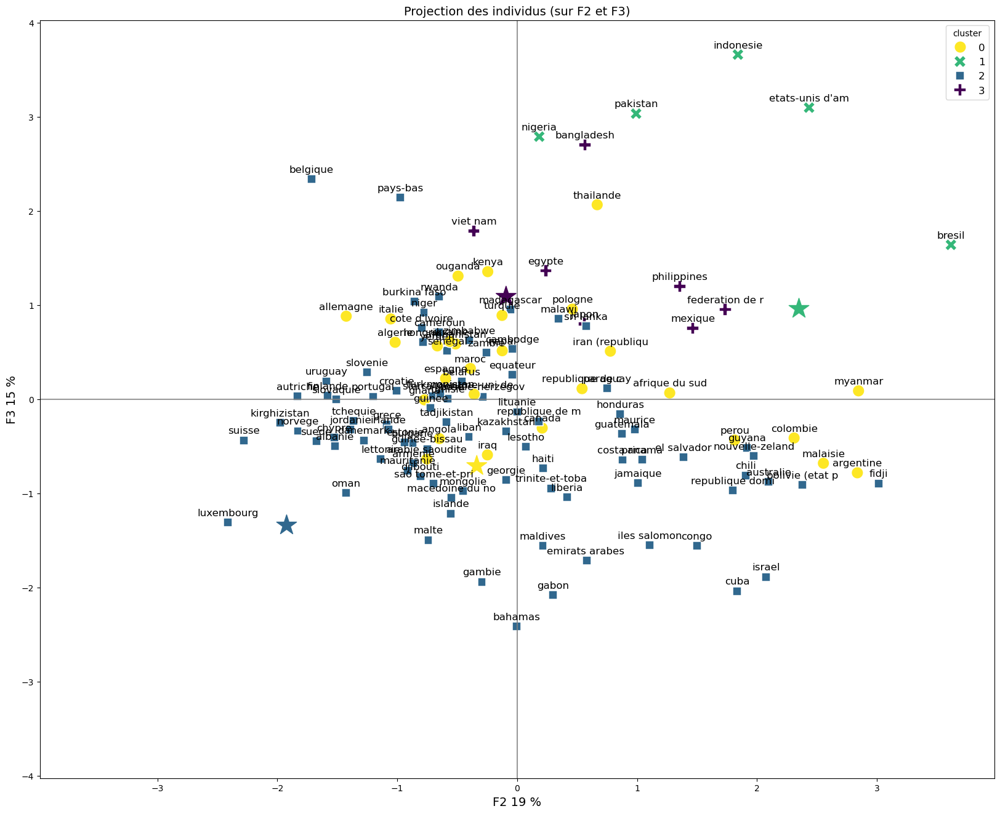

In [64]:
# Afficher le plane factorial avec les clusters en differents coleurs :
x_y = [1,2]
display_factorial_planes_with_centroid(X_proj, x_y, centroids_proj, pca, labels=names, figsize=(20,16), clusters=kmeans.labels_, marker="o")

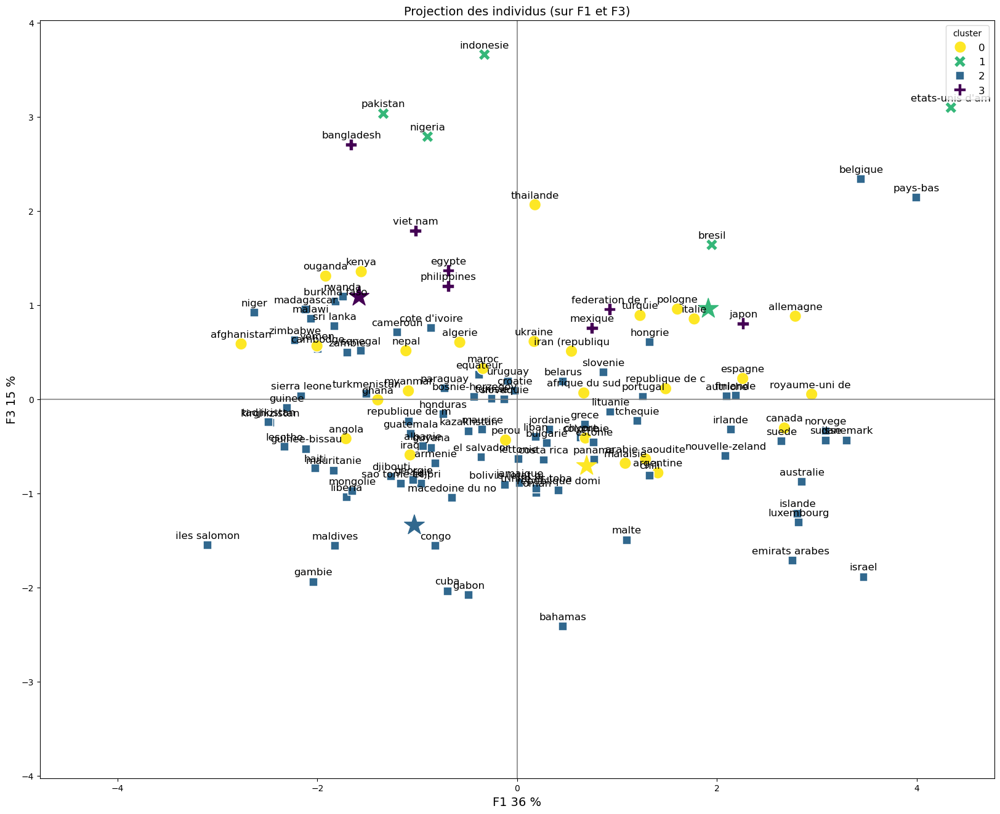

In [65]:
# Afficher le plane factorial avec les clusters en differents coleurs :
x_y = [0,2]
display_factorial_planes_with_centroid(X_proj, x_y, centroids_proj, pca, labels=names, figsize=(20,16), clusters=kmeans.labels_, marker="o")

In [66]:
# Conclusions les analyse de regroupement sur les données brutes:
print("Conclusions les analyse de regroupement sur les données brutes:\n")
print("Les mêmes conclusions que pour le classification hiérarchique. \nL'analyse de regroupement sur les données brutes ne donne pas de résultats satisfaisants. \nLa plupart des pays étant regroupés dans les mêmes clusters, Et les groupes visualisés sur la projection de factoriel ont montré un motif très dispersé. \nNous souhaiterions un regroupement plus performant, permettant de mieux distinguer les différences entre les pays.")

Conclusions les analyse de regroupement sur les données brutes:

Les mêmes conclusions que pour le classification hiérarchique. 
L'analyse de regroupement sur les données brutes ne donne pas de résultats satisfaisants. 
La plupart des pays étant regroupés dans les mêmes clusters, Et les groupes visualisés sur la projection de factoriel ont montré un motif très dispersé. 
Nous souhaiterions un regroupement plus performant, permettant de mieux distinguer les différences entre les pays.


<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">2.2.2 - Classifications sur les données d'ACP</h3>
</div>

<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 10px; color: RGB(255,255,255); ">2.2.2.1 - Classifications ascendante hierarchical - sur les données ACP </h3>
</div>

In [67]:
# les données ACP (les variables dimensions reduits)
#df_proj.drop(columns=["F5","F6"],inplace=True)
#df_proj.drop(columns=["cluster"],inplace=True)
X = df_proj.copy()
X.head()


,F1,F2,F3,F4,F5
pays_norm,,,,,
afghanistan,-2.762390,-0.512928,0.586367,-0.017980,-0.136168
afrique du sud,0.667697,1.272820,0.065873,0.374918,0.286360
albanie,-0.940517,-1.518790,-0.499018,0.212253,-0.468431
algerie,-0.573947,-1.017158,0.603959,-0.480990,-0.661312
allemagne,2.784917,-1.425005,0.881123,0.696496,-0.612836


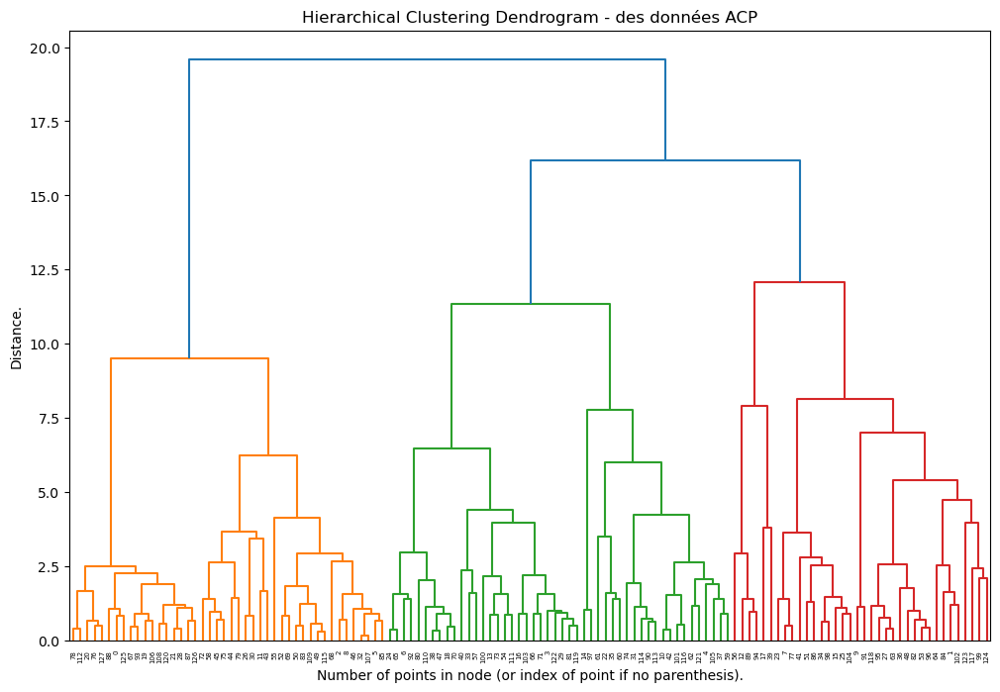

In [68]:
# Calculer les distances utilisant la méthode de Ward:
Z = linkage(X, method="ward")

# Afficher le dendrogramme: 
fig, ax = plt.subplots(1, 1, figsize=(12, 8))

_ = dendrogram(Z, ax=ax)

plt.title("Hierarchical Clustering Dendrogram - des données ACP")
plt.xlabel("Number of points in node (or index of point if no parenthesis).")
plt.ylabel("Distance.")
plt.show()

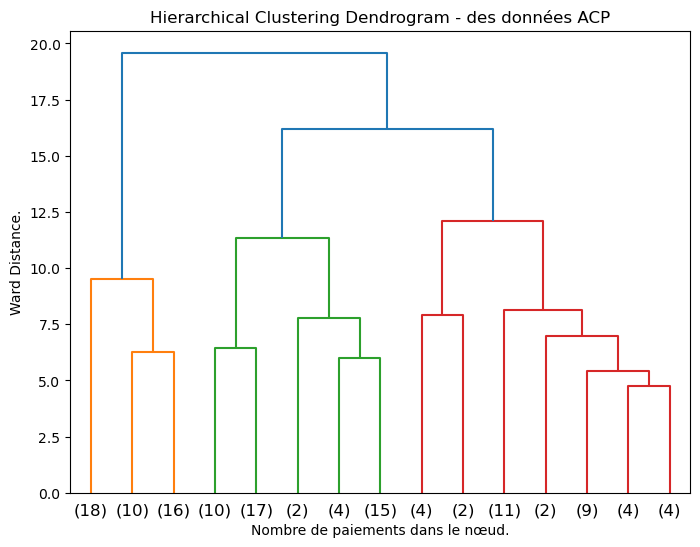

In [176]:
fig, ax = plt.subplots(1, 1, figsize=(8, 6))

_ = dendrogram(Z, p=15, truncate_mode="lastp", ax=ax)

plt.title("Hierarchical Clustering Dendrogram - des données ACP")
plt.xlabel("Nombre de paiements dans le nœud.")
plt.ylabel("Ward Distance.")
plt.show()



In [70]:
#  les arguments p=3, truncate_mode="level"signifient que l'on ne va afficher que les clusters issus de 3 noeuds.
#fig, ax = plt.subplots(1, 1, figsize=(12, 8))

#_ = dendrogram(Z, p=5, truncate_mode="level", ax=ax)

#plt.title("Hierarchical Clustering Dendrogram - des données ACP")
#plt.xlabel("Number of points in node (or index of point if no parenthesis).")
#plt.show()

In [71]:
# Défini le nombre de clusters que l'on souhaite:
k = 4
print("Nombres de clusters:", k)
print("L'analyse de regroupement indique 3 groupes distincts, mais compte tenu de l'objectif de notre travail, \navoir plus de groupes avec moins de pays dans chaque groupe est plus facile à gérer et peut nous fournir des informations supplémentaires entre ces groupes.\n\n")
print("Nous pouvons déjà constater ici que le regroupement des données ACP (que les données brutes) sépare mieux les pays entre les groupes (plus de pays par groupe).".format(k))


Nombres de clusters: 4
L'analyse de regroupement indique 3 groupes distincts, mais compte tenu de l'objectif de notre travail, 
avoir plus de groupes avec moins de pays dans chaque groupe est plus facile à gérer et peut nous fournir des informations supplémentaires entre ces groupes.


Nous pouvons déjà constater ici que le regroupement des données ACP (que les données brutes) sépare mieux les pays entre les groupes (plus de pays par groupe).


In [72]:
# On instancie un estimateur     
cah = AgglomerativeClustering(n_clusters=k, linkage="ward")

# On entraine l'estimateur 
cah.fit(X)

# Pour être plus clair, nous allons utiliser des lettres plutôt que des nombres:
dd = {i:j for i,j in enumerate(list("abcde"))}
labels = [dd[i] for i in cah.labels_]
labels[:10]

# Ajoutons nos labels à X
X["cluster"] = labels
X.head()


# Ajoutons nos labels à données ACP (X) et données brute (XX) 
X["cluster"] = labels

XX = df
XX["cluster"] = labels
df_cluster_agglo_pca = XX
XX.head()


,population,consumations,DIR2,consumption_trend,GNI_per_capita,distance_km,LPI,UPS,cluster
pays_norm,,,,,,,,,
afghanistan,36296113.0,1.53,0.527273,-0.038929,530.0,5597.877813,1.95,24.835282,b
afrique du sud,57009756.0,35.69,0.221622,0.532500,5850.0,8654.323509,3.38,63.331108,c
albanie,2884169.0,16.36,0.808511,-0.399762,4700.0,1605.053520,2.66,55.980276,b
algerie,41389189.0,6.38,0.007576,-0.015833,4440.0,1337.880037,2.45,71.322791,a
allemagne,82658409.0,19.47,0.121815,-0.029048,44730.0,440.324090,4.20,80.984254,a


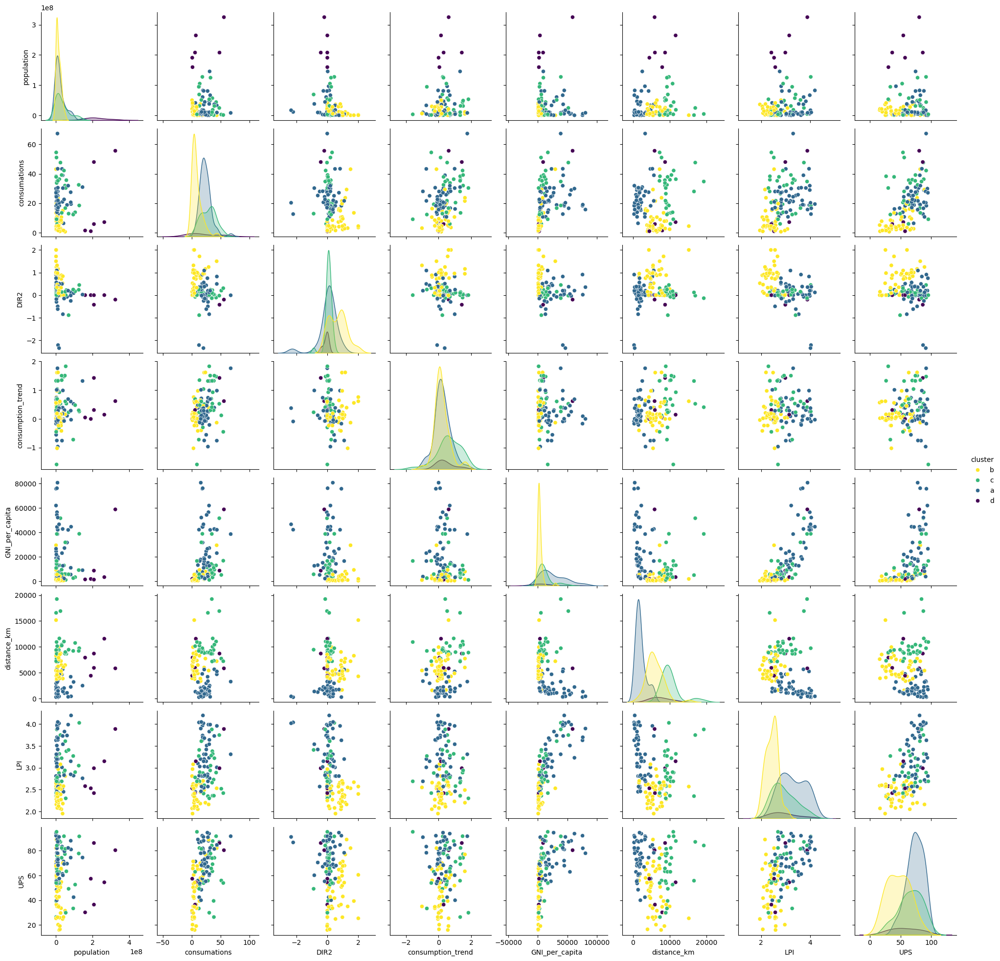

In [73]:
# Observons nos clusters sur le pairplot: 
colors = [cmap(x) for x in np.linspace(0, 1, k)] 
sns.pairplot(XX, hue="cluster", palette=colors)

In [74]:
# Afficher les pays pour chaque cluster : 

# Applique ensuite la fonction fclustersde scipypour définir les clusters : 
clusters = fcluster(Z, k, criterion='maxclust')

# Faire une table de contingence pour identifier les pays dans chaque cluster
crosstab = pd.crosstab(names, clusters, dropna=False)
crosstab.rename_axis(columns="cluster", index="theme", inplace=True)
crosstab

# Ranger les données
df_list = pd.DataFrame({"name" : names, "cluster" : clusters})
df_list.head()

# Afficher les pays
for i in range(1, 6) : 
    # on fait une selection
    sub_df = df_list.loc[df_list.cluster == i]

    # le cluster en question
    print(f"cluster : {i}")

    # on extrait les noms et les themes de chaque ligne
    names_list = sub_df.name.values
    #themes_list = sub_df.theme.values

    # on créé une liste de couple nom/theme
    ziped = names_list 
    txt = names_list

    # on transforme en str
    txt = " / ".join(txt)
 
    # on print
    print(txt)
    print("\n\n")

    


cluster : 1
afghanistan / albanie / angola / armenie / bahamas / burkina faso / cambodge / cameroun / congo / cote d'ivoire / cuba / djibouti / gabon / gambie / georgie / ghana / guinee / guinee-bissau / haiti / iles salomon / iraq / kenya / kirghizistan / lesotho / liberia / macedoine du no / madagascar / malawi / maldives / mauritanie / mongolie / nepal / niger / ouganda / rwanda / sao tome-et-pri / senegal / sierra leone / sri lanka / tadjikistan / turkmenistan / yemen / zambie / zimbabwe



cluster : 2
algerie / allemagne / arabie saoudite / autriche / belarus / belgique / bosnie-herzegov / bulgarie / canada / chypre / croatie / danemark / egypte / emirats arabes  / espagne / estonie / federation de r / finlande / grece / hongrie / iran (republiqu / irlande / islande / israel / italie / jordanie / kazakhstan / lettonie / liban / lituanie / luxembourg / malte / maroc / norvege / oman / pays-bas / pologne / portugal / republique de m / royaume-uni de  / slovaquie / slovenie / suede /

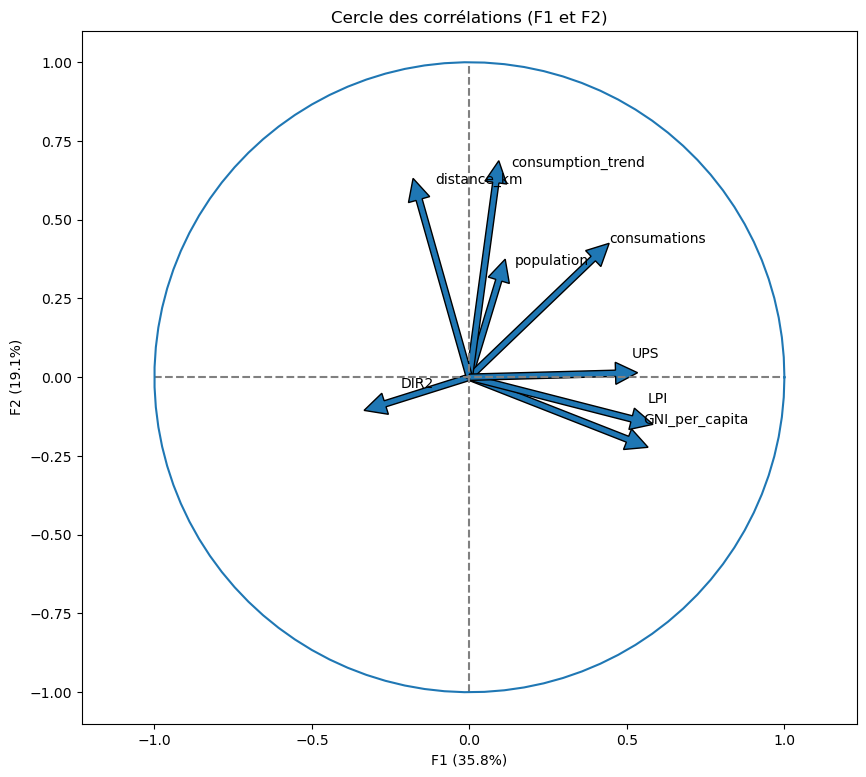

In [75]:
# Cercle des corrélations F1 et F2 (comme un rappel)
x_y = (0,1)
x_y
correlation_graph(pca, x_y, features)

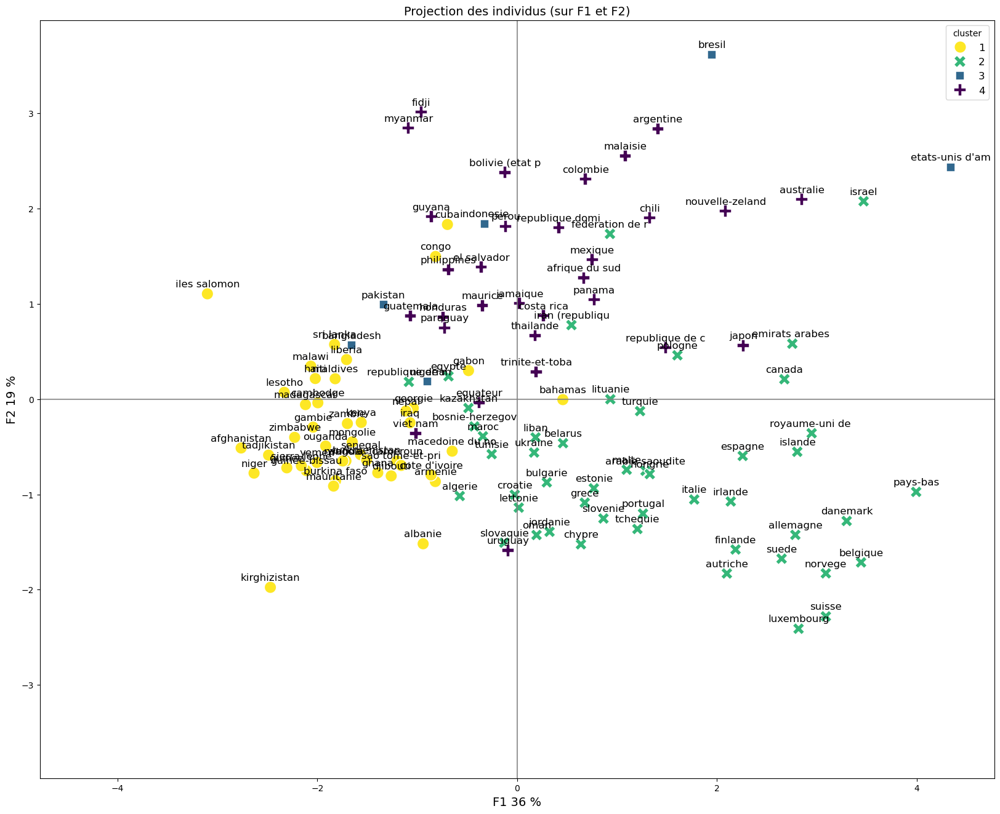

<Figure size 640x480 with 0 Axes>

In [76]:
# Afficher le plane factorial avec les clusters en differents coleurs :
x_y = [0,1]
#display_factorial_planes(X_proj, x_y, pca, labels=names, figsize=(20,16), clusters=X["cluster"], marker="o")
#display_factorial_planes_with_centroid(X_proj, x_y, None, pca, labels_pays=names, labels_clust_nr=labels_nr, figsize=(20,16), clusters=clusters, marker="o")
display_factorial_planes_with_centroid(X_proj, x_y, None, pca, labels=names, figsize=(20,16), clusters=clusters, marker="o")
plt.savefig("PF_F1F2_dat_red.png", transparent=True)

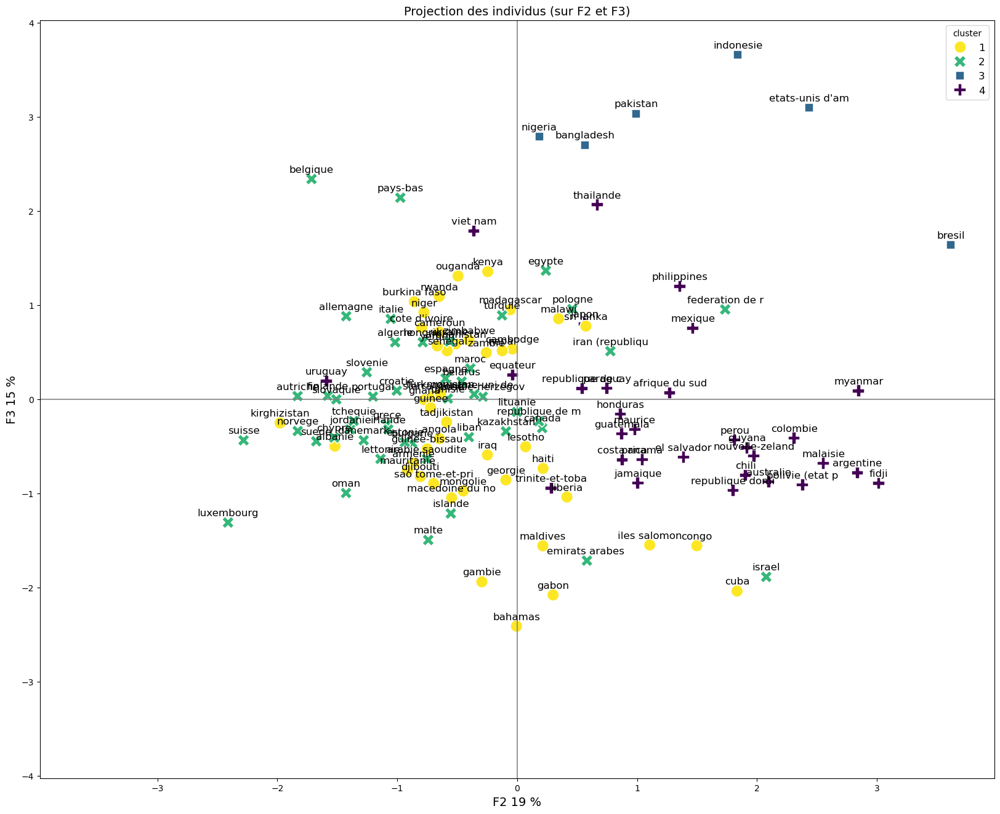

In [77]:
# Afficher le plane factorial avec les clusters en differents coleurs :
x_y = [1,2]
#display_factorial_planes(X_proj, x_y, pca, labels=names, figsize=(20,16), clusters=X["cluster"], marker="o")
display_factorial_planes_with_centroid(X_proj, x_y, None, pca, labels=names, figsize=(20,16), clusters=clusters, marker="o")



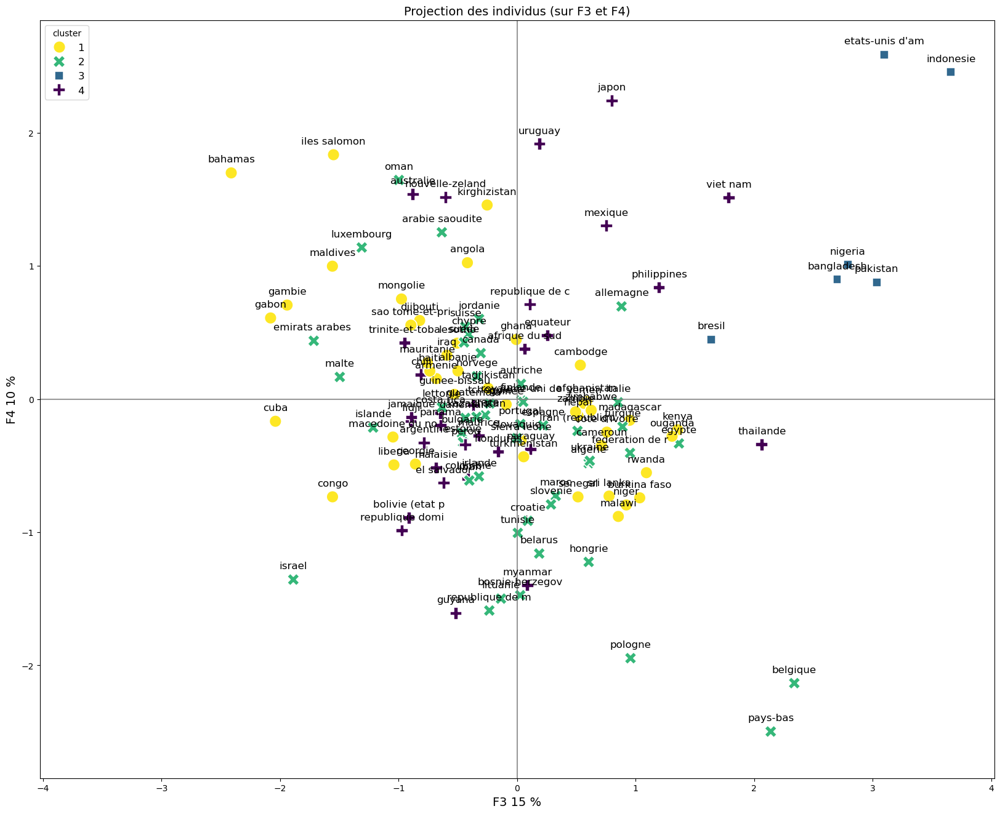

In [78]:
# Afficher le plane factorial avec les clusters en differents coleurs :
x_y = [2,3]
#display_factorial_planes(X_proj, x_y, pca, labels=names, figsize=(20,16), clusters=X["cluster"], marker="o")
display_factorial_planes_with_centroid(X_proj, x_y, None, pca, labels=names, figsize=(20,16), clusters=clusters, marker="o")


In [79]:
# Conclusions les analyse de regroupement sur les ACP:
print("Conclusions les analyse de regroupement sur les données ACP:\n")
print("Les résultats de l'analyse de regroupement des données ACP sont bien plus satisfaisants que ceux obtenus avec les données brutes.")

print("Les pays étaient bien répartis entre les groupes, et la visualisation de ces groupes sur le pairplot et la projection des observations le long des composantes principales a montré une nette séparation entre eux.")


Conclusions les analyse de regroupement sur les données ACP:

Les résultats de l'analyse de regroupement des données ACP sont bien plus satisfaisants que ceux obtenus avec les données brutes.
Les pays étaient bien répartis entre les groupes, et la visualisation de ces groupes sur le pairplot et la projection des observations le long des composantes principales a montré une nette séparation entre eux.


<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 10px; color: RGB(255,255,255); ">2.2.2.2 - Classifications k-means - sur les données ACP </h3>
</div>

In [110]:
# les données ACP (les variables dimensions reduits)
#XX.drop(columns=["cluster"],inplace=True)
#df_proj.drop(columns=["cluster"],inplace=True)
#df_proj.drop(columns=["F5","F6"],inplace=True)
X = df_proj.copy()
X.head()

,F1,F2,F3,F4,F5
pays_norm,,,,,
afghanistan,-2.762390,-0.512928,0.586367,-0.017980,-0.136168
afrique du sud,0.667697,1.272820,0.065873,0.374918,0.286360
albanie,-0.940517,-1.518790,-0.499018,0.212253,-0.468431
algerie,-0.573947,-1.017158,0.603959,-0.480990,-0.661312
allemagne,2.784917,-1.425005,0.881123,0.696496,-0.612836


In [111]:
# Une liste vide pour enregistrer les inerties :  
intertia_list = [ ]

# Notre liste de nombres de clusters : 
k_list = range(1, 6)

# Pour chaque nombre de clusters : 
for k in k_list : 
    
    # On instancie un k-means pour k clusters
    kmeans = KMeans(n_clusters=k)
    
    # On entraine
    kmeans.fit(X)
    
    # On enregistre l'inertie obtenue : 
    intertia_list.append(kmeans.inertia_)


c:\Users\matil\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\matil\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\matil\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\matil\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Window

L'inertie diminue drastiquement jusqu'à 3 clusters


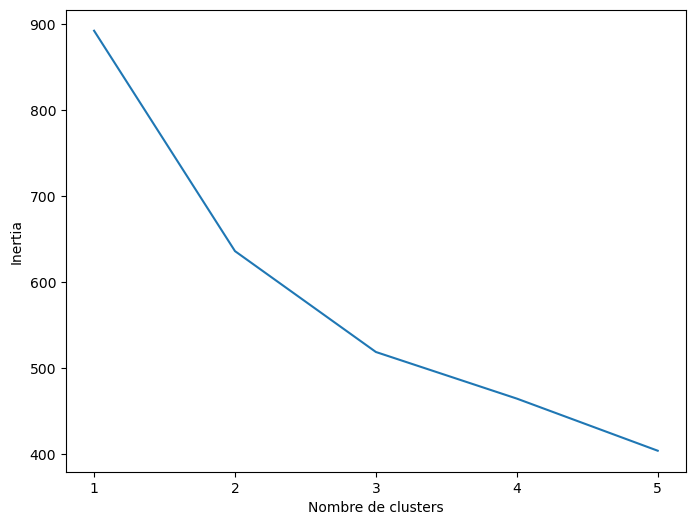

In [174]:
fig, ax = plt.subplots(1, 1, figsize=(8, 6))

ax.set_ylabel("Inertia")
ax.set_xlabel("Nombre de clusters")

ax.plot(k_list, intertia_list)
ax.set_xticks(range(1,6,1))
print("L'inertie diminue drastiquement jusqu'à 3 clusters")

In [113]:
# Défini le nombre de clusters que l'on souhaite:
print("Le graphique indique que le nombre de clusters augmente jusqu'à 3 ou 4 clusters. \n\nPour les besoins de notre étude, 4 clusters comprenant moins de pays chacun, sont plus faciles à gérer, \net nous pourrions ainsi découvrir des différences supplémentaires et plus subtiles entre des clusters plus proches.")
k=4

Le graphique indique que le nombre de clusters augmente jusqu'à 3 ou 4 clusters. 

Pour les besoins de notre étude, 4 clusters comprenant moins de pays chacun, sont plus faciles à gérer, 
et nous pourrions ainsi découvrir des différences supplémentaires et plus subtiles entre des clusters plus proches.


In [114]:
# Les clusters que nous avons obtenus
kmeans = KMeans(n_clusters=k)
kmeans.fit(X)
#kmeans.labels_

# nous allons utiliser des lettres plutôt que des nombres: 
dd = {i:j for i,j in enumerate(list("abcdefgh"))}

labels = [dd[i] for i in kmeans.labels_]

# Ajoutons nos labels à données ACP (X) et données brute (XX) 
X["cluster"] = labels

XX = df
XX["cluster"] = labels
df_cluster_kmeans_pca = XX
XX.head()

c:\Users\matil\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,population,consumations,DIR2,consumption_trend,GNI_per_capita,distance_km,LPI,UPS,cluster,cluster_nr
pays_norm,,,,,,,,,,
afghanistan,36296113.0,1.53,0.527273,-0.038929,530.0,5597.877813,1.95,24.835282,a,3
afrique du sud,57009756.0,35.69,0.221622,0.532500,5850.0,8654.323509,3.38,63.331108,b,0
albanie,2884169.0,16.36,0.808511,-0.399762,4700.0,1605.053520,2.66,55.980276,d,3
algerie,41389189.0,6.38,0.007576,-0.015833,4440.0,1337.880037,2.45,71.322791,d,3
allemagne,82658409.0,19.47,0.121815,-0.029048,44730.0,440.324090,4.20,80.984254,c,1


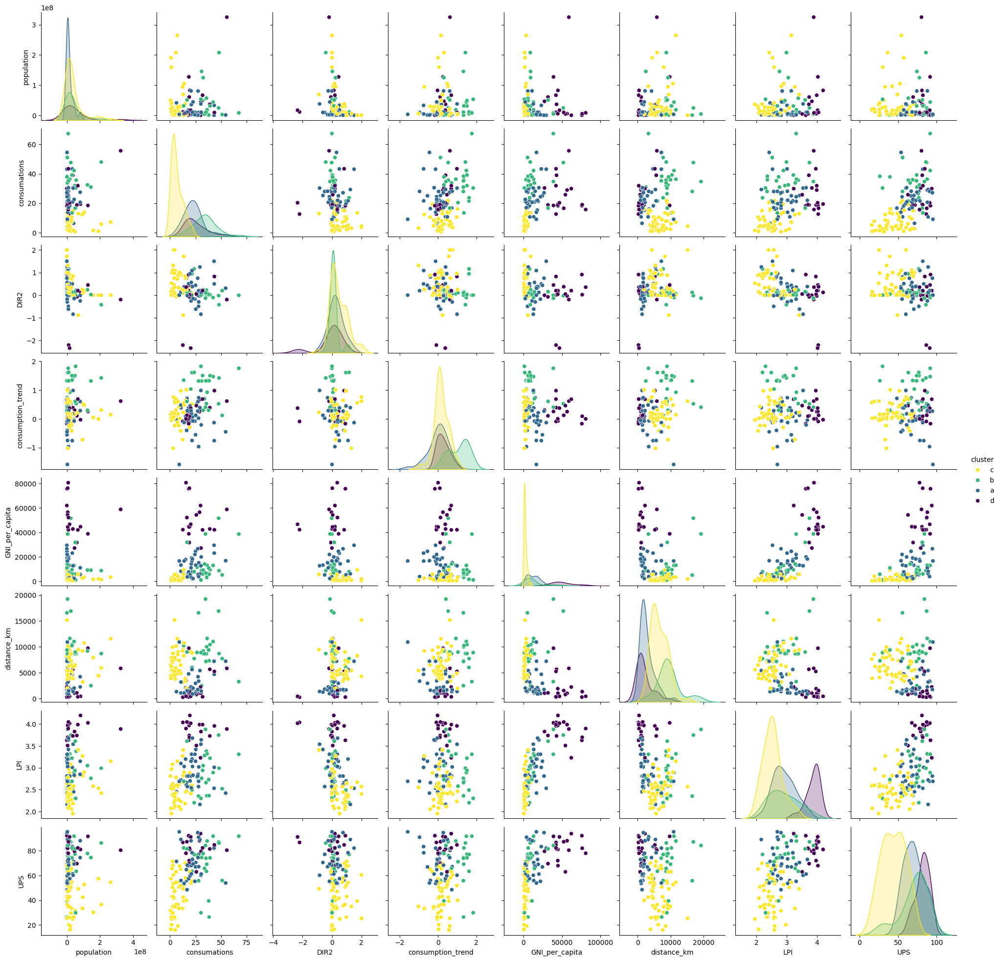

In [86]:
# Affichons le graphique:
colors = [cmap(x) for x in np.linspace(0, 1, k)] 
sns.pairplot(XX, hue="cluster", palette=colors)

In [115]:
# Enregistrons nos centroids 
centroids = kmeans.cluster_centers_
centroids.shape


(4, 5)

In [116]:
# scaler les centroids
centroids_scaled = scaler.fit_transform(centroids)
centroids_scaled.shape

(4, 5)

In [117]:
# Créons un DataFrame pour plus de clarté : ADJUST AFTER NUMBER OF CLUSTERS AND COMPONENTS
centroids_proj = pd.DataFrame(centroids, 
                              columns = ["F1", "F2", "F3", "F4", "F5"], 
                              index=["cluster_1", "cluster_2", "cluster_3", "cluster_4"])
centroids_proj 


,F1,F2,F3,F4,F5
cluster_1,-1.431205,0.000550,1.205831,0.045245,0.299716
cluster_2,0.492947,1.784247,-0.503312,-0.211382,0.219560
cluster_3,2.068060,-0.790254,0.101454,-0.060073,-0.085542
cluster_4,-1.046659,-0.539296,-0.544292,0.157759,-0.273112


In [118]:
# Valeurs des centroïdes sur les données originales 
centroids_brute = pca.inverse_transform(centroids) 
centroids_brute = pd.DataFrame(centroids_brute, 
                              columns = features, 
                              index=["cluster_1", "cluster_2", "cluster_3", "cluster_4"])

centroids_brute 

,population,consumations,DIR2,consumption_trend,GNI_per_capita,distance_km,LPI,UPS
cluster_1,0.540489,-0.918791,-0.411916,-0.468988,-0.797346,0.398455,-0.501716,-1.010977
cluster_2,0.056498,1.004754,-0.200069,1.269042,-0.077808,0.998147,-0.038158,0.325149
cluster_3,0.033103,0.490429,-0.544933,-0.279808,1.166505,-0.862668,1.161951,0.922319
cluster_4,-0.419782,-0.451346,0.841620,-0.301653,-0.362573,-0.225371,-0.579702,-0.290711


In [119]:
# Valeurs des centroïdes sur les données originales 
centroids_brute = pca.inverse_transform(centroids_scaled) 
centroids_brute = pd.DataFrame(centroids_brute, 
                              columns = features, 
                              index=["cluster_1", "cluster_2", "cluster_3", "cluster_4"])

centroids_brute 


,population,consumations,DIR2,consumption_trend,GNI_per_capita,distance_km,LPI,UPS
cluster_1,0.587948,-0.965040,-0.842581,-1.037097,-0.479375,0.981032,-0.032417,-0.968020
cluster_2,-1.015866,0.982586,-0.891593,1.620893,-0.277026,0.793689,-0.177153,0.069406
cluster_3,0.025699,0.253286,-0.307710,-0.123731,0.813382,-1.241923,0.752599,0.670189
cluster_4,0.402218,-0.270832,2.041883,-0.460065,-0.056981,-0.532798,-0.543029,0.228425


In [120]:
# Valeurs des centroïdes sur les données originales 
centroids_brute = pca.inverse_transform(centroids) 
centroids_brute = pd.DataFrame(centroids_brute, 
                              columns = features, 
                              index=["cluster_1", "cluster_2", "cluster_3", "cluster_4"])

centroids_brute 


,population,consumations,DIR2,consumption_trend,GNI_per_capita,distance_km,LPI,UPS
cluster_1,0.540489,-0.918791,-0.411916,-0.468988,-0.797346,0.398455,-0.501716,-1.010977
cluster_2,0.056498,1.004754,-0.200069,1.269042,-0.077808,0.998147,-0.038158,0.325149
cluster_3,0.033103,0.490429,-0.544933,-0.279808,1.166505,-0.862668,1.161951,0.922319
cluster_4,-0.419782,-0.451346,0.841620,-0.301653,-0.362573,-0.225371,-0.579702,-0.290711


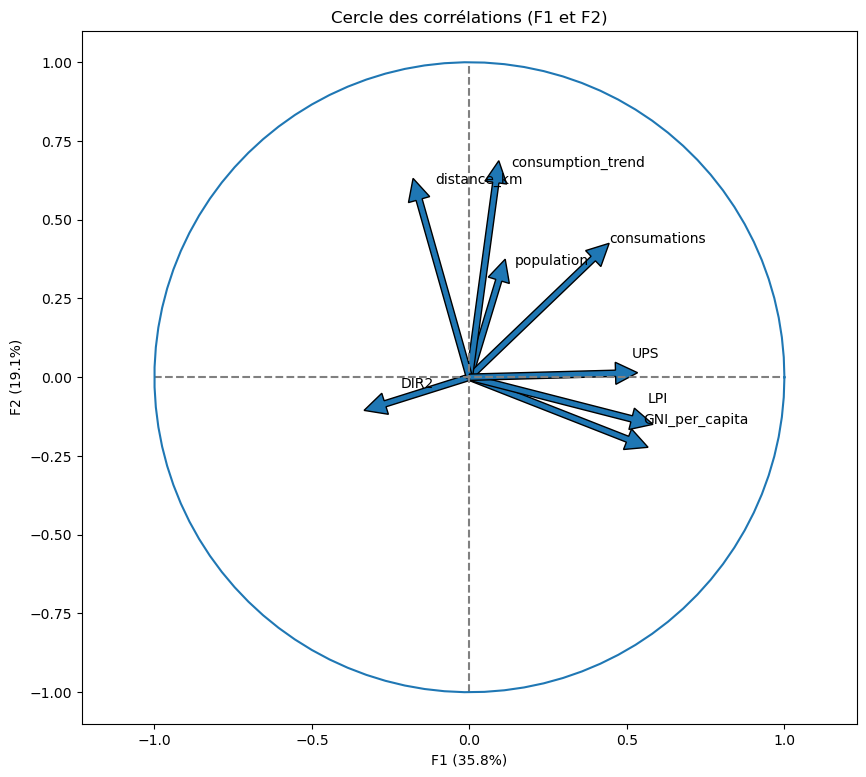

In [121]:
# Cercle des corrélations F1 et F2
x_y = (0,1)
x_y
correlation_graph(pca, x_y, features)

In [122]:
# Ajouter la variable de numéro de cluster
df_cluster_kmeans_pca["cluster_nr"] = kmeans.labels_

Figure saved


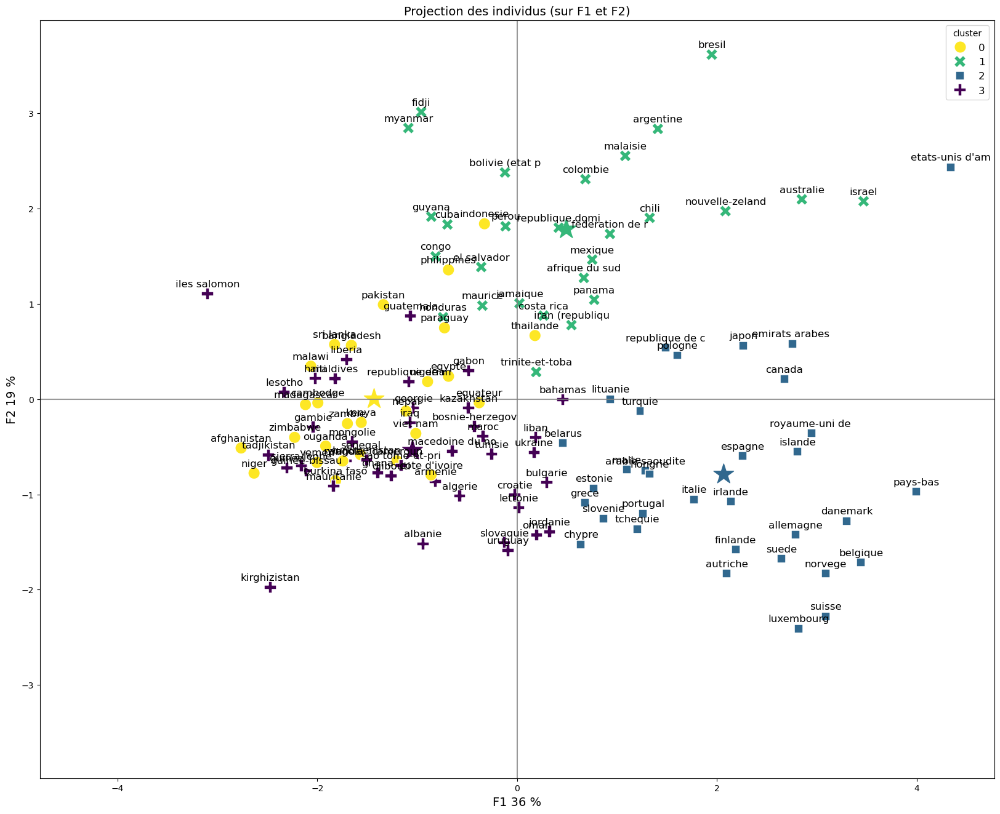

In [124]:
# Afficher le plane factorial avec les clusters en differents coleurs :
x_y = [0,1]
display_factorial_planes_with_centroid(X_proj, x_y, centroids_proj, pca, labels=names, figsize=(20,16), clusters=kmeans.labels_, marker="o",save="Resultats/Projection_F1F2_kmeans_pca_3clust.jpeg")
#plt.savefig("Resultats/Projection_F1F2_kmeans_pca.jpeg")
plt.show()

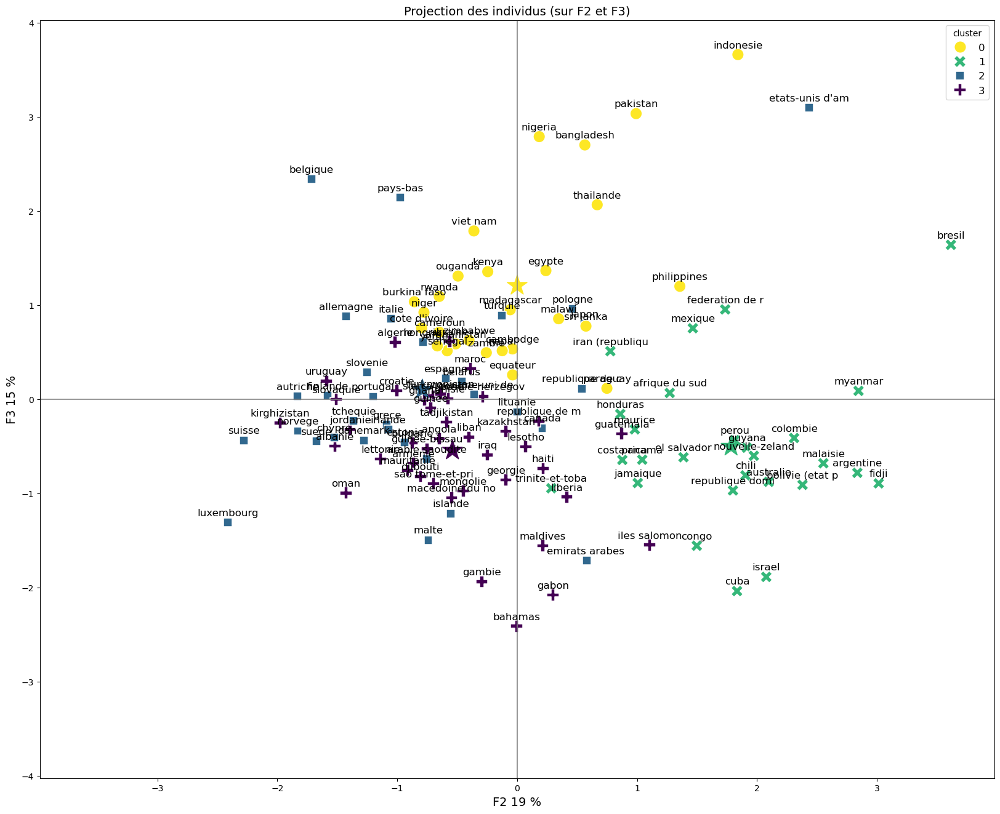

In [125]:
# Afficher le plane factorial avec les clusters en differents coleurs :
x_y = [1,2]
display_factorial_planes_with_centroid(X_proj, x_y, centroids_proj, pca, labels=names, figsize=(20,16), clusters=kmeans.labels_, marker="o")

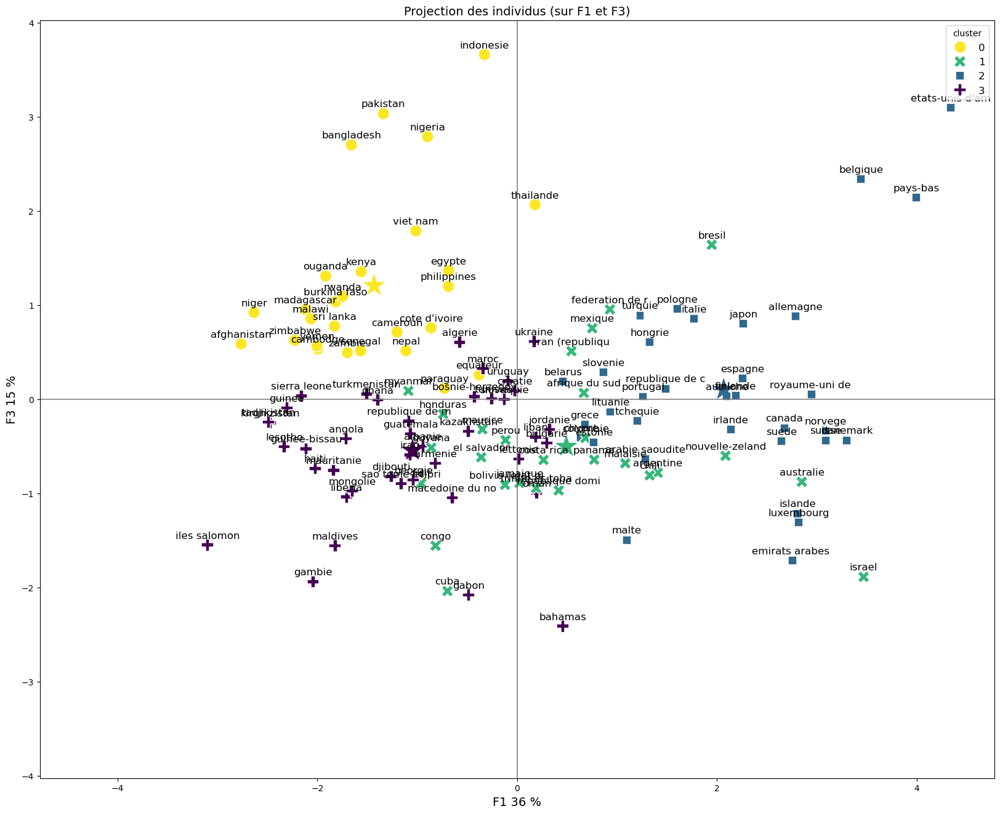

In [126]:
# Afficher le plane factorial avec les clusters en differents coleurs :
x_y = [0,2]
display_factorial_planes_with_centroid(X_proj, x_y, centroids_proj, pca, labels=names, figsize=(20,16), clusters=kmeans.labels_, marker="o")


In [127]:
# Conclusions les analyse de regroupement sur les ACP:
print("Conclusions les analyse de regroupement sur les données ACP:\n")
print("Les conclusions sont les mêmes que pour la méthode de classification hiérarchique. \nLes résultats de l'analyse de regroupement des données ACP sont bien plus satisfaisants que ceux obtenus avec les données brutes.")

print("Les pays étaient bien répartis entre les groupes, et la visualisation de ces groupes sur le pairplot et la projection des observations le long des composantes principales a montré une nette séparation entre eux.")


Conclusions les analyse de regroupement sur les données ACP:

Les conclusions sont les mêmes que pour la méthode de classification hiérarchique. 
Les résultats de l'analyse de regroupement des données ACP sont bien plus satisfaisants que ceux obtenus avec les données brutes.
Les pays étaient bien répartis entre les groupes, et la visualisation de ces groupes sur le pairplot et la projection des observations le long des composantes principales a montré une nette séparation entre eux.


<div style="background-color: RGB(27, 161, 226);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 3 - Visualiser les résultats</h2>
</div>

In [ ]:
# Enregistrez l'ensemble de données avec les resultats des clusters - hierarchical clustering sur les données ACP
df_cluster_agglo_pca.to_csv("Resultats/df_cluster_agglo_pca_avril8.csv")

In [ ]:
# Enregistrez l'ensemble de données avec les resultats des clusters - K-means clustering sur les données ACP
df_cluster_kmeans_pca.to_csv("Resultats/df_cluster_kmeans_pca_avril8.csv")

In [ ]:
#df_cluster_kmeans_pca = pd.read_csv("Resultats/df_cluster_kmeans_pca2.csv", index_col=0)

In [128]:
# Les données brutes, avec les clusters associés issus de l'analyse d'écart k-means, ont été appliquées aux données PCA projetées
df_cluster_kmeans_pca.head(3)

,population,consumations,DIR2,consumption_trend,GNI_per_capita,distance_km,LPI,UPS,cluster,cluster_nr
pays_norm,,,,,,,,,,
afghanistan,36296113.0,1.53,0.527273,-0.038929,530.0,5597.877813,1.95,24.835282,a,0
afrique du sud,57009756.0,35.69,0.221622,0.532500,5850.0,8654.323509,3.38,63.331108,b,1
albanie,2884169.0,16.36,0.808511,-0.399762,4700.0,1605.053520,2.66,55.980276,d,3


In [ ]:
# recupérer les codes ISO3 des pays
df_cluster_kmeans_pca["iso3"] = iso3

# Créer des colonnes distinctes pour chaque cluster - pour représenter graphiquement cluster par cluster
cluster_cols = pd.get_dummies(df_cluster_kmeans_pca["cluster"]).mul(df_cluster_kmeans_pca["cluster"], axis=0) #.replace({"":"NaN"})
cluster_cols["cd"] = cluster_cols["c"] + cluster_cols["d"]
#cluster_cols = cluster_cols.replace({"":"NaN"})

df_cluster_kmeans_pca = pd.concat([df_cluster_kmeans_pca, cluster_cols], axis=1)
df_cluster_kmeans_pca["France"] = np.repeat(np.NaN, len(df_cluster_kmeans_pca))
df_cluster_kmeans_pca.head()

,population,consumations,DIR2,consumption_trend,GNI_per_capita,distance_km,LPI,UPS,cluster,cluster_nr,iso3,a,b,c,d,cd,France
pays_norm,,,,,,,,,,,,,,,,,
afghanistan,36296113.0,1.53,0.527273,-0.038929,530.0,5597.877813,1.95,24.835282,a,0,AFG,a,,,,,NaN
afrique du sud,57009756.0,35.69,0.221622,0.532500,5850.0,8654.323509,3.38,63.331108,b,1,ZAF,,b,,,,NaN
albanie,2884169.0,16.36,0.808511,-0.399762,4700.0,1605.053520,2.66,55.980276,d,3,ALB,,,,d,d,NaN
algerie,41389189.0,6.38,0.007576,-0.015833,4440.0,1337.880037,2.45,71.322791,d,3,DZA,,,,d,d,NaN
allemagne,82658409.0,19.47,0.121815,-0.029048,44730.0,440.324090,4.20,80.984254,c,2,DEU,,,c,,c,NaN


In [130]:
# Definir les couleurs des figures
n = df_cluster_kmeans_pca["cluster"].nunique()
cmap = plt.get_cmap("viridis_r")
colors = [cmap(x) for x in np.linspace(0, 1, n)]

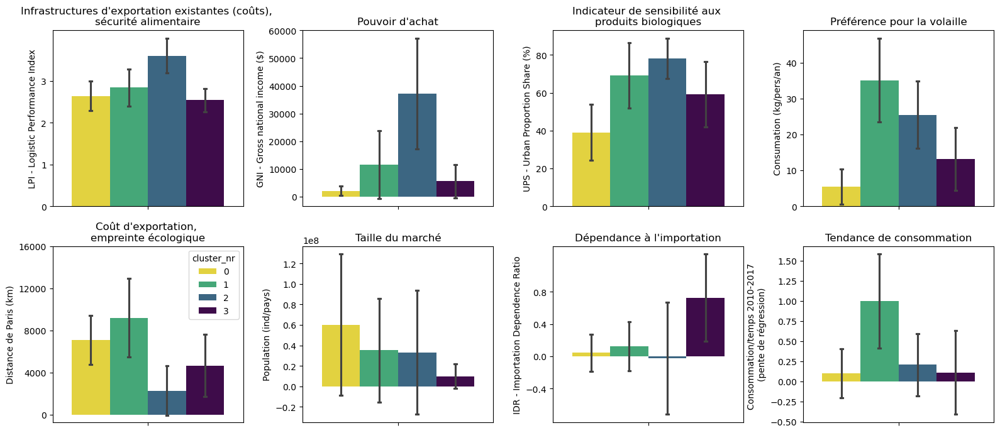

In [131]:
# Diagramme à barres avec barres d'erreur pour indiquer la valeur moyenne de chaque variable
n = df_cluster_kmeans_pca["cluster"].nunique()
cmap = plt.get_cmap("viridis_r")
colors = [cmap(x) for x in np.linspace(0, 1, n)]

fig, ax = plt.subplots(2,4, figsize=(16, 7))
#fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=df_cluster_kmeans_pca, y="LPI", hue="cluster_nr", errorbar="sd", capsize=0.05, ax=ax[0,0], palette=colors, legend=False).set(
    ylabel="LPI - Logistic Performance Index",
    title="Infrastructures d'exportation existantes (coûts), \nsécurité alimentaire",
    yticks=range(0,4,1)
)
sns.barplot(data=df_cluster_kmeans_pca, y="GNI_per_capita", hue="cluster_nr", errorbar="sd", capsize=0.05, ax=ax[0,1], palette=colors, legend=False).set(
    ylabel="GNI - Gross national income ($)",
    title="Pouvoir d'achat"
)
sns.barplot(data=df_cluster_kmeans_pca, y="UPS", hue="cluster_nr", errorbar="sd", capsize=0.05, ax=ax[0,2], palette=colors, legend=False).set(
    ylabel="UPS - Urban Proportion Share (%)",
    title="Indicateur de sensibilité aux \nproduits biologiques"
)
sns.barplot(data=df_cluster_kmeans_pca, y="consumations", hue="cluster_nr", errorbar="sd", capsize=0.05, ax=ax[0,3], palette=colors, legend=False).set(
    ylabel="Consumation (kg/pers/an)",
    title="Préférence pour la volaille"
)

sns.barplot(data=df_cluster_kmeans_pca, y="distance_km", hue="cluster_nr", errorbar="sd", capsize=0.05, ax=ax[1,0], palette=colors).set(
    ylabel="Distance de Paris (km)",
    title="Coût d'exportation, \nempreinte écologique",
    yticks=range(0,16500,4000)
)
sns.barplot(data=df_cluster_kmeans_pca, y="population", hue="cluster_nr", errorbar="sd", capsize=0.05, ax=ax[1,1], palette=colors, legend=False).set(
    ylabel="Population (ind/pays)",
    title="Taille du marché"
)
sns.barplot(data=df_cluster_kmeans_pca, y="DIR2", hue="cluster_nr", errorbar="sd", capsize=0.05, ax=ax[1,2], palette=colors, legend=False).set(
    ylabel="IDR - Importation Dependence Ratio",
    title="Dépendance à l'importation",
    yticks=[-0.4,0,0.4,0.8]
)
sns.barplot(data=df_cluster_kmeans_pca, y="consumption_trend", hue="cluster_nr", errorbar="sd", capsize=0.05, ax=ax[1,3], palette=colors, legend=False).set(
    ylabel="Consommation/temps 2010-2017 \n(pente de régression)",
    title="Tendance de consommation"
)
fig.tight_layout()
plt.savefig("Resultats/Cluster_vars_res_kmeans.jpeg")
#plt.savefig("Cluster_variable_summaryT.jpeg", transparent=True)
plt.show()

In [133]:
# Tracer la carte du monde avec GeoPandas
#%pip install geopandas


In [135]:
# Telecharger les données géographiques du monde
import geopandas as gpd           

world = gpd.read_file(
    "https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_countries.zip"
)

world.columns[world.columns.str.contains("ISO")]

world.loc[world["SOV_A3"] == "NOR","ISO_A3"] = "NOR"  # correction du code ISO de la Norvège


In [ ]:
# Junction les données de cluster avec les données géographiques
world = world.merge(
    df_cluster_kmeans_pca,
    left_on="ISO_A3",
    right_on="iso3",
    how="left"
)
world.head(3)

# Marquer la France dans le dataframe world
world.loc[(world["SOVEREIGNT"] == ("France")) & (world["ADMIN"] == ("France")), "France"] = "aa"

C:\Users\matil\AppData\Local\Temp\ipykernel_33012\519053339.py:11: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'aa' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  world.loc[(world["SOVEREIGNT"] == ("France")) & (world["ADMIN"] == ("France")), "France"] = "aa"


In [137]:
# Ajouter une variale de couleur pour les clusters
color_dict = {
    0: colors[0],
    1: colors[1],
    2: colors[2],
    3: colors[3],
}

world["color"] = world["cluster"].map(color_dict)
world.head(3)

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,cluster,cluster_nr,iso3,a,b,c,d,cd,France,color
0,Admin-0 country,1,6,Fiji,FJI,0,2,Sovereign country,1,Fiji,...,b,1.0,FJI,,b,,,,NaN,NaN
1,Admin-0 country,1,3,United Republic of Tanzania,TZA,0,2,Sovereign country,1,United Republic of Tanzania,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Admin-0 country,1,7,Western Sahara,SAH,0,2,Indeterminate,1,Western Sahara,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


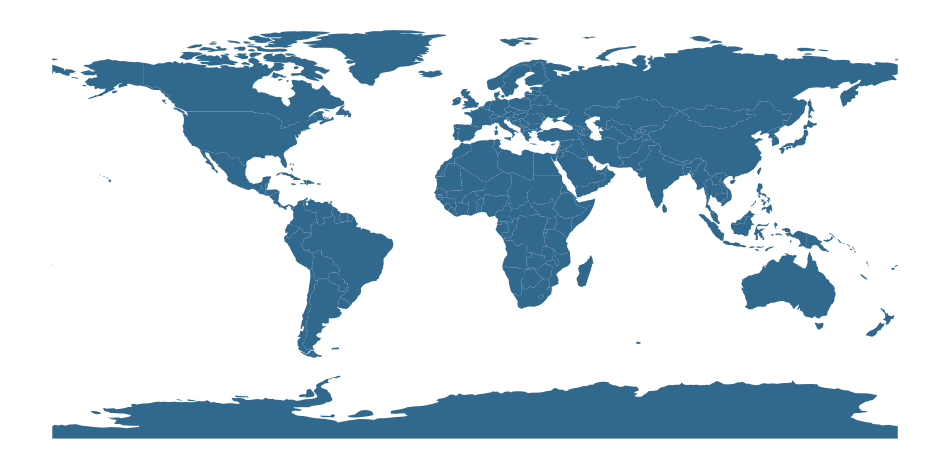

In [139]:
# Tracez la carte du monde en une seule couleur
fig, ax = plt.subplots(figsize=(12, 6))

world.plot(
    color= (0.190631, 0.407061, 0.556089, 1.0),
    #color=(0.267004, 0.004874, 0.329415, 1.0),   # ← one single color
    #edgecolor="black",   # optional borders
    linewidth=0.3,
    ax=ax
)

ax.set_axis_off()

ax.set_axis_off()

fig.savefig(
    "Resultats/Cluster_map_kmeans_all_color1.png",
    dpi=300,
    transparent=True,
    bbox_inches="tight"
)


plt.show()

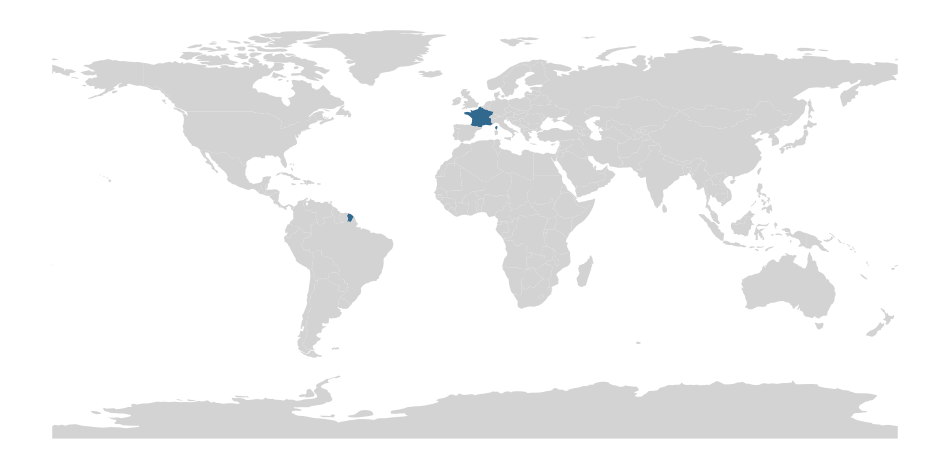

In [140]:
# Plot - le monde avec France indiquee en une couleur différente
fig, ax = plt.subplots(figsize=(12, 6))
from matplotlib.colors import ListedColormap
cmap = ListedColormap(["#31688E"])

world.plot(
    column="France",
    cmap=cmap,
    #color = 'red',legend=False,
    ax=ax,
    missing_kwds={"color": "lightgrey"}
)
ax.set_axis_off()

fig.savefig(
    "Resultats/Cluster_map_kmeans_France.png",
    dpi=300,
    transparent=True,
    bbox_inches="tight"
)

plt.show()

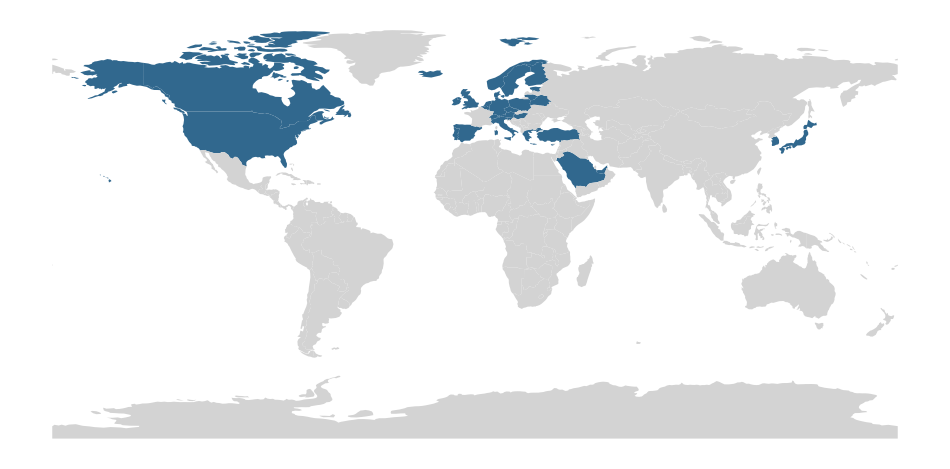

In [165]:
# Plot - le monde avec France indiquee en une couleur différente
fig, ax = plt.subplots(figsize=(12, 6))
from matplotlib.colors import ListedColormap
cmap = ListedColormap(["#31688E"])

world.plot(
    column="c",
    cmap=cmap,
    #color = 'red',legend=False,
    ax=ax,
    missing_kwds={"color": "lightgrey"}
)
ax.set_axis_off()

fig.savefig(
    "Resultats/Cluster_map_kmeans_pays_ideal.png",
    dpi=300,
    transparent=True,
    bbox_inches="tight"
)

plt.show()

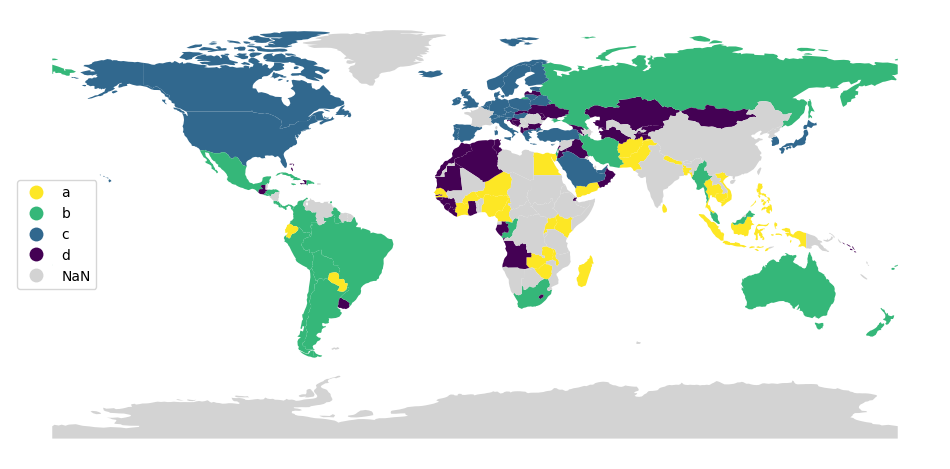

In [170]:
# Tracez la carte du monde avec les 4 clusters
fig, ax = plt.subplots(figsize=(12, 6))

world.plot(
    column="cluster",
    cmap="viridis_r",
    #palette=colors,
    legend=True,
    ax=ax,
    missing_kwds={"color": "lightgrey"},
     legend_kwds={
        "loc": "center left"  
    }
)

ax.set_axis_off()

fig.savefig(
    "Resultats/Cluster_map_kmeans_allClust.png",
    dpi=300,
    transparent=True,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Liste de pays dans cluster c - cluster que nous avons identifié comme le plus proche de la France, 
# et qui pourrait être notre marché idéal pour l'exportation de poulet biologique
cluster_c = world[world["cluster"] == "c"]["SOVEREIGNT"].tolist()

np.sort(cluster_c)

array(['Austria', 'Belarus', 'Belgium', 'Canada', 'Cyprus', 'Czechia',
       'Denmark', 'Estonia', 'Finland', 'Germany', 'Greece', 'Hungary',
       'Iceland', 'Ireland', 'Italy', 'Japan', 'Lithuania', 'Luxembourg',
       'Netherlands', 'Norway', 'Poland', 'Portugal', 'Saudi Arabia',
       'Slovenia', 'South Korea', 'Spain', 'Sweden', 'Switzerland',
       'Turkey', 'United Arab Emirates', 'United Kingdom',
       'United States of America'], dtype='<U24')

In [203]:
# Liste de pays dans cluster a 
cluster_a = world[world["cluster"] == "a"]["SOVEREIGNT"].tolist()

np.sort(cluster_a)

array(['Afghanistan', 'Bangladesh', 'Burkina Faso', 'Cambodia',
       'Cameroon', 'Ecuador', 'Egypt', 'Indonesia', 'Ivory Coast',
       'Kenya', 'Madagascar', 'Malawi', 'Nepal', 'Niger', 'Nigeria',
       'Pakistan', 'Paraguay', 'Philippines', 'Rwanda', 'Senegal',
       'Sri Lanka', 'Thailand', 'Uganda', 'Vietnam', 'Yemen', 'Zambia',
       'Zimbabwe'], dtype='<U12')

In [201]:
# Liste de pays dans cluster b 
cluster_b = world[world["cluster"] == "b"]["SOVEREIGNT"].tolist()

np.sort(cluster_b)

array(['Argentina', 'Australia', 'Bolivia', 'Brazil', 'Chile', 'Colombia',
       'Costa Rica', 'Cuba', 'Dominican Republic', 'El Salvador', 'Fiji',
       'Guyana', 'Honduras', 'Iran', 'Israel', 'Jamaica', 'Malaysia',
       'Mexico', 'Myanmar', 'New Zealand', 'Panama', 'Peru',
       'Republic of the Congo', 'Russia', 'South Africa',
       'Trinidad and Tobago'], dtype='<U21')

In [202]:
# Liste de pays dans cluster d 
cluster_d = world[world["cluster"] == "d"]["SOVEREIGNT"].tolist()

np.sort(cluster_d)

array(['Albania', 'Algeria', 'Angola', 'Armenia',
       'Bosnia and Herzegovina', 'Bulgaria', 'Croatia', 'Djibouti',
       'Gabon', 'Gambia', 'Georgia', 'Ghana', 'Guatemala', 'Guinea',
       'Guinea-Bissau', 'Haiti', 'Iraq', 'Jordan', 'Kazakhstan',
       'Kyrgyzstan', 'Latvia', 'Lebanon', 'Lesotho', 'Liberia',
       'Mauritania', 'Moldova', 'Mongolia', 'Morocco', 'North Macedonia',
       'Oman', 'Sierra Leone', 'Slovakia', 'Solomon Islands',
       'Tajikistan', 'The Bahamas', 'Tunisia', 'Turkmenistan', 'Ukraine',
       'Uruguay'], dtype='<U22')

In [ ]:
# Fin de script